# Etapa 3. Regresión logística múltiple — modelo final (v4)
**Reto clima: vegetación y contaminación (SIMA, Monterrey)**

Modelo de dependencia: probabilidad de que la concentración **mensual** de un contaminante (PM10, PM2.5, NO2 y O3) sea *alta* —según los límites de las Normas Oficiales Mexicanas publicados por el SIMA de Nuevo León— en función de la vegetación (NDVI, cobertura verde), la meteorología y la ubicación de cada estación. El objetivo principal es medir **qué tan significativa es la vegetación alrededor de las estaciones**.

Estructura: 0. Configuración · 1. Datos y ubicación · 2. Variable respuesta (NOM) · 3. Preparación · 4. Multicolinealidad · 5. Modelo y resultados (incl. **vegetación por radio**) · 6. Validación de supuestos · 7. Eficiencia (**con vs. sin vegetación**) · 8. Variables más importantes · 9. Comparación final · 10. Lectura de resultados

---
**Cambios respecto a v3**
1. **O3 es solo variable respuesta.** Se quitó como predictor (opción `INCLUIR_O3` y el paso "+ O3" de la tabla de autocorrelación) y se agregó como cuarto contaminante a modelar.
2. **Umbral normativo en lugar de la mediana.** "Alto" = el promedio mensual supera el límite de la NOM (tabla del SIMA Nuevo León). El umbral es fijo, así que ya no depende del periodo de entrenamiento y significa lo mismo en entrenamiento y prueba.
3. **Cinco radios de vegetación** (100, 300, 500, 1000 y 2000 m; el de 2000 m viene en la nueva base). Todos los modelos usan la **misma muestra** (meses con NDVI en los cinco radios), así que AIC y métricas son comparables entre radios.
4. **Modelo sin vegetación:** mismas variables que el modelo final, sin `ndvi` ni `verde`. Se compara con prueba de razón de verosimilitud, AIC, y desempeño fuera de muestra (corte temporal y walk-forward), con intervalo bootstrap de la diferencia de AUC.

# Configuración

In [30]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve, confusion_matrix,
                             precision_score, recall_score, f1_score, brier_score_loss, log_loss)

warnings.simplefilter("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 40)

# --- Parámetros que se pueden cambiar ---
RUTA = "C:\\Users\\ludio\\MA203B-Multivariados\\Exploracion_descriptiva\\tablas\\base_analitica_mensual.csv"   # ajusta la ruta si el archivo está en otra carpeta
RADIOS = [100, 300, 500, 1000, 2000]  # radios (m) de NDVI y cobertura verde que se comparan
RADIO = 2000                          # radio del modelo principal (diagnósticos detallados, secciones 4, 6 y 8)
CONTAMINANTES = ["PM10", "PM2.5", "NO2", "O3"]   # O3 es solo variable respuesta (no entra como predictor)

# --- Umbrales normativos (ver sección 2). Unidades de la base: µg/m³ (PM) y ppb (NO2, O3) ---
UMBRALES = {"PM10": 50,    # NOM-025-SSA1-2021, límite 24 h (valor publicado por SIMA NL)
            "PM2.5": 25,   # NOM-025-SSA1-2021, límite 24 h
            "NO2": 21,     # NOM-023-SSA1-2021, promedio anual 0.021 ppm
            "O3": 30}      # NOM-020-SSA1-2021 no tiene límite de largo plazo: 50 % del límite de 8 h (0.060 ppm). Ver sección 2

INCLUIR_ANIO = True                   # indicadora de 2025 (cambio común de nivel entre años)
MIN_MESES_2025 = 6                    # anio2025 entra solo si el entrenamiento tiene al menos estos meses de 2025
                                      # (con 1-2 meses, el "efecto 2025" se confunde con la estacionalidad de esos meses)
INCLUIR_Y_REZAGADA = True             # estado del mes anterior de la misma estación (autologístico)
MUESTRA_COMUN = True                  # usar solo meses con NDVI en todos los radios (hace comparables los modelos)

FECHA_CORTE = "2025-07"               # primer mes de PRUEBA. Entrenamiento: 2024-01 a 2025-06
VARS_UBICACION = ["lat", "elev"]      # lon y elev casi idénticas (r = -0.97)
INICIO_WALK_FORWARD = 12              # entrena con los primeros 12 meses y predice mes a mes hasta el 24
RIDGE_C = 0.3                         # penalización L2 de la especificación C (efecto fijo por estación)
N_BOOT = 1000                         # réplicas bootstrap para la diferencia de AUC (con vs. sin vegetación)

# Carga de datos y ubicación de las estaciones
Coordenadas transcritas del documento *Ubicación de las estaciones de SIMA 2025* y convertidas a grados decimales (igual que en v3).

⚠️ La estación `NO2` (Noroeste 2) **no tiene relación** con el contaminante NO2.

In [31]:
UBIC_DOC = [
    (1,  "25°39’55’’N 100°14’37’’W", 500, "Sureste",    "SE"),
    (2,  "25°44’41’’N 100°15’11’’W", 474, "Noreste",    "NE"),
    (3,  "25°40’33’’N 100°20’18’’W", 562, "Centro",     "CE"),
    (4,  "25°45’46’’N 100°22’09’’W", 568, "Noroeste",   "NO"),
    (5,  "25°40’32’’N 100°27’29’’W", 674, "Suroeste",   "SO"),
    (6,  "25°48’01’’N 100°35’04’’W", 702, "Noroeste 2", "NO2"),
    (7,  "25°47’55’’N 100°19’38’’W", 503, "Norte",      "NTE"),
    (8,  "25°46’38’’N 100°11’17’’W", 432, "Noreste 2",  "NE2"),
    (9,  "25°38’45’’N 100°05’43’’W", 387, "Sureste 2",  "SE2"),
    (10, "25°39’54’’N 100°24’46’’W", 636, "Suroeste 2", "SO2"),
    (11, "25°36’04’’N 99°59’57’’W",  334, "Sureste",    "SE3"),
    (12, "25°37’01’’N 100°16’26’’W", 555, "Sur",        "SUR"),
    (13, "25°43’47’’N 100°18’36’’W", 520, "Norte 2",    "NTE2"),
    (14, "25°47’26’’N 100°04’42’’W", 346, "Noreste 3",  "NE3"),
    (15, "25°46’06’’N 100°27’49’’W", 607, "Noroeste 3", "NO3"),
]
def dms_a_decimal(s):
    partes = re.findall(r"(\d+)°\s*(\d+)[’'′]\s*(\d+)[’'′]{1,2}\s*([NSEW])", s)
    assert len(partes) == 2, f"No se pudo leer: {s}"
    return [(-1 if h in 'WS' else 1) * (int(g) + int(m) / 60 + int(sg) / 3600) for g, m, sg, h in partes]

UBIC = pd.DataFrame([(sim, *dms_a_decimal(coord), elev, zona, num) for num, coord, elev, zona, sim in UBIC_DOC],
                    columns=["estacion", "lat", "lon", "elev", "zona", "no"]).set_index("estacion")

base = pd.read_csv(RUTA)
assert set(base["estacion"]) == set(UBIC.index), "Las estaciones de la base y del documento no coinciden"
faltan = [f"{v}_{r}" for r in RADIOS for v in ("ndvi", "verde") if f"{v}_{r}" not in base]
assert not faltan, f"Faltan columnas de vegetación en la base: {faltan}"
base = base.merge(UBIC[["lat", "lon", "elev", "zona"]], left_on="estacion", right_index=True, how="left")
print(base.shape)

# Cobertura verde (%) por estación y radio (constante en el tiempo) + NDVI medio de los 24 meses
fijos = UBIC.join(base.groupby("estacion")[[f"verde_{r}" for r in RADIOS]].first()) \
            .join(base.groupby("estacion")[[f"ndvi_{r}" for r in RADIOS]].mean().add_suffix("_medio"))
display(fijos.drop(columns="no").sort_values(f"verde_{RADIO}", ascending=False))

(360, 43)


,lat,lon,elev,zona,verde_100,verde_300,verde_500,verde_1000,verde_2000,ndvi_100_medio,ndvi_300_medio,ndvi_500_medio,ndvi_1000_medio,ndvi_2000_medio
estacion,,,,,,,,,,,,,,
NE3,25.791,-100.078,346,Noreste 3,24.130,56.295,66.321,64.827,72.278,0.395,0.402,0.399,0.352,0.391
SE3,25.601,-99.999,334,Sureste,0.000,4.371,10.550,14.231,30.509,0.189,0.200,0.251,0.291,0.345
NO3,25.768,-100.464,607,Noroeste 3,0.000,0.000,5.026,15.646,28.202,0.293,0.186,0.178,0.226,0.279
SUR,25.617,-100.274,555,Sur,0.000,0.000,1.145,3.604,24.203,0.284,0.196,0.206,0.235,0.337
SE,25.665,-100.244,500,Sureste,0.000,0.233,1.128,10.780,21.386,0.375,0.231,0.226,0.263,0.304
SE2,25.646,-100.095,387,Sureste 2,0.000,0.276,7.693,6.564,14.006,0.190,0.258,0.308,0.293,0.293
SO2,25.665,-100.413,636,Suroeste 2,0.000,0.000,0.147,2.851,12.753,0.237,0.217,0.206,0.193,0.240
NE2,25.777,-100.188,432,Noreste 2,0.000,0.000,0.649,2.722,11.377,0.052,0.126,0.155,0.191,0.231
NO,25.763,-100.369,568,Noroeste,0.000,0.000,0.391,0.983,11.266,0.305,0.202,0.137,0.134,0.179


Nota sobre el radio de 100 m: solo **NE3** tiene cobertura verde distinta de 0 (24 %). En ese radio `verde_100` funciona en la práctica como una indicadora "NE3 vs. el resto", así que su coeficiente no se puede separar de cualquier otra característica de NE3. En PM2.5 (sin datos en NE3) `verde_100` es constante y **no se estima**.

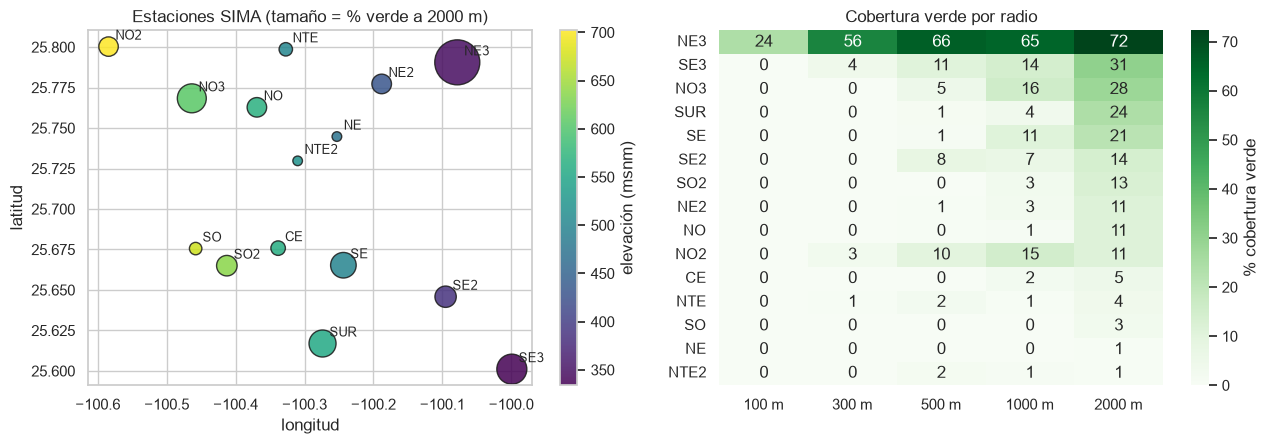

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
sc = axes[0].scatter(fijos.lon, fijos.lat, s=40 + 14 * fijos[f"verde_{RADIO}"], c=fijos.elev, cmap="viridis", edgecolor="k", alpha=.85)
for e, r in fijos.iterrows(): axes[0].annotate(e, (r.lon, r.lat), xytext=(5, 5), textcoords="offset points", fontsize=9)
plt.colorbar(sc, ax=axes[0], label="elevación (msnm)")
axes[0].set_xlabel("longitud"); axes[0].set_ylabel("latitud"); axes[0].set_title(f"Estaciones SIMA (tamaño = % verde a {RADIO} m)")
sns.heatmap(fijos[[f"verde_{r}" for r in RADIOS]].sort_values(f"verde_{RADIOS[-1]}", ascending=False).set_axis([f"{r} m" for r in RADIOS], axis=1),
            annot=True, fmt=".0f", cmap="Greens", cbar_kws={"label": "% cobertura verde"}, ax=axes[1])
axes[1].set_title("Cobertura verde por radio"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

# Variable respuesta binaria con umbral normativo (NOM)
Se usan los límites que el SIMA de Nuevo León publica en su página de normatividad (Secretaría de Medio Ambiente de NL), que corresponden a las NOM de Salud Ambiental vigentes:

| Contaminante | Norma | Límites publicados por SIMA NL | Unidades base | Umbral usado | Criterio |
|---|---|---|---|---|---|
| PM10 | NOM-025-SSA1-2021 | 50 µg/m³ (24 h) · 20 µg/m³ (anual) | µg/m³ | **50** | promedio mensual > límite de 24 h |
| PM2.5 | NOM-025-SSA1-2021 | 25 µg/m³ (24 h) · 10 µg/m³ (anual) | µg/m³ | **25** | promedio mensual > límite de 24 h |
| NO2 | NOM-023-SSA1-2021 | 0.106 ppm (1 h) · 0.021 ppm (anual) | ppb | **21** | promedio mensual > límite anual |
| O3 | NOM-020-SSA1-2021 | 0.090 ppm (1 h) · 0.060 ppm (8 h) | ppb | **30** | promedio mensual > 50 % del límite de 8 h (no hay límite de largo plazo) |

**Por qué estas elecciones.** La base solo trae **promedios mensuales**, y las NOM se evalúan con promedios de 1 h, 8 h, 24 h o anuales. Se eligió, para cada contaminante, el límite que tiene sentido comparar con un promedio mensual:
- **PM10 y PM2.5:** el límite **anual** (20 y 10 µg/m³) lo supera prácticamente todo mes (≈ 96–100 %), así que no distingue nada. Se usa el de **24 h**: "alto" significa que *el día típico del mes* supera el límite diario.
- **NO2:** el límite anual (21 ppb) es precisamente un promedio de largo plazo, así que la comparación es directa. El de 1 h (106 ppb) nunca se alcanza con promedios mensuales.
- **O3:** la NOM-020 solo tiene límites de 1 h y 8 h (máximos diarios); **ningún promedio mensual de la base llega a 60 ppb** (máximo ≈ 54 ppb), así que el límite tal cual dejaría 0 meses "altos" y no se podría ajustar el modelo. Se usa 30 ppb = 50 % del límite de 8 h, que es un umbral fijo anclado a la norma y deja una proporción de meses altos razonable. **Es una decisión del equipo**: se puede cambiar en `UMBRALES`.
- **Valores graduales:** la NOM-025 baja sus límites de forma escalonada (año 1: 70/41, año 3: 60/33, año 5: 50/25 µg/m³ para PM10/PM2.5 en 24 h). Para 2024–2025 el valor escalonado sería el del año 3 (60/33), pero el SIMA NL publica ya el valor final (50/25); se usa ese. Con 33 µg/m³ solo 10 meses de PM2.5 quedarían "altos", muy pocos para estimar el modelo (ver la tabla de alternativas abajo).

El umbral es **fijo**: ya no se calcula con el entrenamiento, por lo que no hay fuga de información y "alto" significa lo mismo en entrenamiento y prueba (lo que recomendaba v3).

In [33]:
base = base.sort_values(["estacion", "fecha_mes"]).reset_index(drop=True)
base["RAINF_log"] = np.log1p(base["RAINF"])
base["humeda"] = (base["temporada"] == "húmeda").astype(int)
base["anio2025"] = (base["fecha_mes"].str[:4] == "2025").astype(int)
base["t"] = (base["fecha_mes"].str[:4].astype(int) - 2024) * 12 + base["fecha_mes"].str[5:7].astype(int) - 1   # 0..23

T_CORTE = (int(FECHA_CORTE[:4]) - 2024) * 12 + int(FECHA_CORTE[5:7]) - 1
print(f"Entrenamiento: t < {T_CORTE} (hasta {base.loc[base.t == T_CORTE - 1, 'fecha_mes'].iloc[0]}) | Prueba: desde {FECHA_CORTE}")

filas = []
for c in CONTAMINANTES:
    for nombre, m in [("entrenamiento", base.t < T_CORTE), ("prueba", base.t >= T_CORTE), ("total", base.t >= 0)]:
        v = base.loc[m, c].dropna()
        filas.append({"contaminante": c, "periodo": nombre, "umbral": UMBRALES[c], "n_validos": len(v),
                      "n_alto (y=1)": int((v > UMBRALES[c]).sum()), "% alto": 100 * (v > UMBRALES[c]).mean(),
                      "máximo mensual": v.max()})
pd.DataFrame(filas).set_index(["contaminante", "periodo"])

Entrenamiento: t < 18 (hasta 2025-06) | Prueba: desde 2025-07


umbral  n_validos  n_alto (y=1)  % alto  \
contaminante periodo                                                  
PM10         entrenamiento      50        264           184  69.697   
             prueba             50         89            21  23.596   
             total              50        353           205  58.074   
PM2.5        entrenamiento      25        165            36  21.818   
             prueba             25         55             5   9.091   
             total              25        220            41  18.636   
NO2          entrenamiento      21        244            42  17.213   
             prueba             21         82            14  17.073   
             total              21        326            56  17.178   
O3           entrenamiento      30        259           102  39.382   
             prueba             30         84            33  39.286   
             total              30        343           135  39.359   

                            máximo mensual  
contaminante periodo                        
PM10         entrenamiento         105.722  
             prueba                 75.615  
             total                 105.722  
PM2.5        entrenamiento          45.462  
             prueba                 34.142  
             total                  45.462  
NO2          entrenamiento          39.784  
             prueba                 28.273  
             total                  39.784  
O3           entrenamiento          53.596  
             prueba                 37.879  
             total                  53.596

In [34]:
# Alternativas de umbral normativo: ¿cuántos meses quedarían "altos"?
ALTERNATIVAS = [("PM10", "24 h, año 1 (70)", 70), ("PM10", "24 h, año 3 — escalonado 2024-25 (60)", 60), ("PM10", "24 h, final / SIMA NL (50)", 50), ("PM10", "anual, final (20)", 20),
                ("PM2.5", "24 h, año 1 (41)", 41), ("PM2.5", "24 h, año 3 — escalonado 2024-25 (33)", 33), ("PM2.5", "24 h, final / SIMA NL (25)", 25), ("PM2.5", "anual (10)", 10),
                ("NO2", "1 h (106 ppb)", 106), ("NO2", "anual (21 ppb)", 21),
                ("O3", "1 h (90 ppb)", 90), ("O3", "8 h, SIMA NL (60 ppb)", 60), ("O3", "50 % del límite de 8 h (30 ppb)", 30)]
alt = pd.DataFrame([{"contaminante": c, "umbral": n, "valor": u, "n alto": int((base[c].dropna() > u).sum()),
                     "% alto": 100 * (base[c].dropna() > u).mean(), "usado": "✔" if u == UMBRALES[c] else ""}
                    for c, n, u in ALTERNATIVAS]).set_index(["contaminante", "umbral"])
alt

valor  n alto  % alto  \
contaminante umbral                                                         
PM10         24 h, año 1 (70)                          70      88  24.929   
             24 h, año 3 — escalonado 2024-25 (60)     60     136  38.527   
             24 h, final / SIMA NL (50)                50     205  58.074   
             anual, final (20)                         20     352  99.717   
PM2.5        24 h, año 1 (41)                          41       4   1.818   
             24 h, año 3 — escalonado 2024-25 (33)     33      10   4.545   
             24 h, final / SIMA NL (25)                25      41  18.636   
             anual (10)                                10     211  95.909   
NO2          1 h (106 ppb)                            106       0   0.000   
             anual (21 ppb)                            21      56  17.178   
O3           1 h (90 ppb)                              90       0   0.000   
             8 h, SIMA NL (60 ppb)                     60       0   0.000   
             50 % del límite de 8 h (30 ppb)           30     135  39.359   

                                                   usado  
contaminante umbral                                       
PM10         24 h, año 1 (70)                             
             24 h, año 3 — escalonado 2024-25 (60)        
             24 h, final / SIMA NL (50)                ✔  
             anual, final (20)                            
PM2.5        24 h, año 1 (41)                             
             24 h, año 3 — escalonado 2024-25 (33)        
             24 h, final / SIMA NL (25)                ✔  
             anual (10)                                   
NO2          1 h (106 ppb)                                
             anual (21 ppb)                            ✔  
O3           1 h (90 ppb)                                 
             8 h, SIMA NL (60 ppb)                        
             50 % del límite de 8 h (30 ppb)           ✔

# Preparación de los datos
Modelo **final (spec. B)**: vegetación (`verde_r`, `ndvi_r`), meteorología (temperatura, humedad, log-lluvia, viento), temporada húmeda, año 2025, estado del mes anterior (`y_rez`) y ubicación (`lat`, `elev`). **O3 ya no es predictor.**

| Modelo | Vegetación | Uso |
|---|---|---|
| **B con vegetación (radio r)** | `verde_r` + `ndvi_r` | modelo final, uno por cada radio |
| **B sin vegetación** | — | mismo modelo sin `verde` ni `ndvi`: mide cuánto aporta la vegetación |
| A | `verde_r` + `ndvi_r`, sin ubicación | sensibilidad (sección 5.2) |
| C | solo `ndvi_r` + efecto fijo por estación (ridge) | sensibilidad: efecto del NDVI *dentro* de cada estación |

- Estandarización (z-score) con media y DE **del entrenamiento**; los OR de continuas se leen por 1 DE, los de binarias de 0 a 1.
- `y_rez` se calcula antes de quitar filas y solo existe si el mes anterior de la misma estación es consecutivo.
- `anio2025` solo entra si el entrenamiento tiene al menos `MIN_MESES_2025` meses de 2025 (afecta al walk-forward: en los primeros pasos solo hay 1–2 meses de 2025 y el coeficiente capturaría la estacionalidad de esos meses, no un cambio entre años).
- Con `MUESTRA_COMUN = True` se usan solo los meses con NDVI en los cinco radios: los modelos con y sin vegetación y entre radios usan **exactamente las mismas filas**.

In [35]:
METEO = ["TOUT", "RH", "RAINF_log", "WSR", "SR"]
NDVI_TODOS = [f"ndvi_{r}" for r in RADIOS]
def veg_cols(r): return [f"verde_{r}", f"ndvi_{r}"]

def preparar(c, radio=None, veg=True, spec="B", corte=None, anio=None, rezago=None):
    # Devuelve dict con y/X/datos de entrenamiento (t < corte) y prueba (t >= corte)
    radio = RADIO if radio is None else radio
    corte = T_CORTE if corte is None else corte
    anio = INCLUIR_ANIO if anio is None else anio
    rezago = INCLUIR_Y_REZAGADA if rezago is None else rezago

    d = base.copy()
    d["y"] = (d[c] > UMBRALES[c]).astype(float).where(d[c].notna())        # umbral normativo fijo
    consecutivo = d.groupby("estacion")["t"].diff() == 1
    d["y_rez"] = d.groupby("estacion")["y"].shift(1).where(consecutivo)

    cont = list(METEO)
    if veg: cont = ([f"verde_{radio}"] if spec in ("A", "B") else []) + [f"ndvi_{radio}"] + cont
    if spec == "B": cont = cont + VARS_UBICACION
    anio = anio and (corte - 12) >= MIN_MESES_2025          # meses de 2025 en el entrenamiento = corte - 12
    extra = ["humeda"] + (["anio2025"] if anio else []) + (["y_rez"] if rezago else [])

    d = d.dropna(subset=["y"] + cont + extra + (NDVI_TODOS if MUESTRA_COMUN else [])).copy()
    trn, tst = d[d.t < corte], d[d.t >= corte]
    mu, sd = trn[cont].mean(), trn[cont].std().replace(0, np.nan)
    estaciones = sorted(trn.estacion.unique())
    def matriz(z):
        X = ((z[cont] - mu) / sd).copy()
        for e in extra: X[e] = z[e]
        if spec == "C":
            for s in estaciones[1:]: X["est_" + s] = (z.estacion == s).astype(float)
        return sm.add_constant(X, has_constant="add")
    Xtr, Xte = matriz(trn), matriz(tst)
    constantes = [k for k in Xtr.columns if k != "const" and not (Xtr[k].std() > 0)]   # p. ej. verde_100 en PM2.5
    Xtr, Xte = Xtr.drop(columns=constantes), Xte.drop(columns=constantes)
    return dict(ytr=trn["y"].astype(int), Xtr=Xtr, dtr=trn, yte=tst["y"].astype(int), Xte=Xte, dte=tst,
                cont=cont, spec=spec, radio=radio, veg=veg, omitidas=constantes)

def ajustar_sm(y, X, grupos):
    return sm.Logit(y, X).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos}, maxiter=300)

def or_p(m, v):
    return (np.exp(m.params[v]), m.pvalues[v]) if v in m.params.index else (np.nan, np.nan)

datos = {c: preparar(c) for c in CONTAMINANTES}
datos_sv = {c: preparar(c, veg=False) for c in CONTAMINANTES}
for c in CONTAMINANTES:   # misma muestra con y sin vegetación
    assert datos[c]["dtr"].index.equals(datos_sv[c]["dtr"].index) and datos[c]["dte"].index.equals(datos_sv[c]["dte"].index)
pd.DataFrame({c: {"n entrenamiento": len(datos[c]["ytr"]), "n prueba": len(datos[c]["yte"]),
                  "eventos (y=1) entren.": int(datos[c]["ytr"].sum()), "eventos (y=1) prueba": int(datos[c]["yte"].sum()),
                  "% y=1 entren.": 100 * datos[c]["ytr"].mean(), "% y=1 prueba": 100 * datos[c]["yte"].mean(),
                  "n estaciones": datos[c]["dtr"]["estacion"].nunique(),
                  "parámetros (con veg.)": datos[c]["Xtr"].shape[1]} for c in CONTAMINANTES}).T

,n entrenamiento,n prueba,eventos (y=1) entren.,eventos (y=1) prueba,% y=1 entren.,% y=1 prueba,n estaciones,parámetros (con veg.)
PM10,191.000,64.000,133.000,15.000,69.634,23.438,15.000,13.000
PM2.5,101.000,29.000,28.000,1.000,27.723,3.448,11.000,13.000
NO2,175.000,56.000,33.000,11.000,18.857,19.643,15.000,13.000
O3,187.000,56.000,85.000,20.000,45.455,35.714,15.000,13.000


# Multicolinealidad (VIF)
Entrenamiento del modelo con vegetación. Primero el detalle del radio principal y luego, para cada radio, el VIF de las dos variables de vegetación y el máximo del modelo.

In [36]:
def vif_serie(X): return pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=X.columns).drop("const")
print(f"VIF, radio {RADIO} m:")
display(pd.DataFrame({c: vif_serie(datos[c]["Xtr"]) for c in CONTAMINANTES}))

filas = []
for r in RADIOS:
    for c in CONTAMINANTES:
        v = vif_serie(preparar(c, radio=r)["Xtr"])
        filas.append({"radio": r, "contaminante": c, "VIF verde": v.get(f"verde_{r}", np.nan), "VIF ndvi": v.get(f"ndvi_{r}", np.nan),
                      "VIF máximo": v.max(), "variable con VIF máximo": v.idxmax()})
print("VIF de la vegetación por radio:")
pd.DataFrame(filas).set_index(["radio", "contaminante"]).unstack("contaminante")[["VIF verde", "VIF ndvi", "VIF máximo"]]

VIF, radio 2000 m:


,PM10,PM2.5,NO2,O3
verde_2000,4.351,11.253,4.580,4.443
ndvi_2000,3.843,6.810,3.830,4.095
TOUT,4.723,4.263,5.024,5.640
RH,2.461,3.986,2.304,2.462
RAINF_log,1.535,1.471,1.589,1.517
WSR,2.075,2.910,2.038,2.022
SR,1.839,4.930,1.966,1.831
lat,1.746,12.873,1.824,1.847
elev,2.147,2.520,2.142,2.096
humeda,4.448,4.100,4.412,4.509


VIF de la vegetación por radio:


VIF verde                    VIF ndvi                    \
contaminante       NO2    O3  PM10  PM2.5      NO2    O3  PM10 PM2.5   
radio                                                                  
100              3.274 2.902 3.092    NaN    1.467 1.490 1.712 1.612   
300              4.493 4.102 4.115  3.114    2.551 2.648 2.831 2.320   
500              4.142 3.852 3.822  5.025    2.976 3.136 3.239 2.281   
1000             3.786 3.514 3.533  4.083    3.240 3.354 3.270 4.925   
2000             4.580 4.443 4.351 11.253    3.830 4.095 3.843 6.810   

             VIF máximo                     
contaminante        NO2    O3  PM10  PM2.5  
radio                                       
100               4.843 5.658 4.711  4.286  
300               4.844 5.634 4.615  4.567  
500               4.834 5.609 4.614  5.025  
1000              4.886 5.613 4.644  6.883  
2000              5.024 5.640 4.723 12.873

# Especificación y resultados del modelo
Logit $\log\frac{p}{1-p} = \beta_0 + \mathbf{x}'\beta + \gamma\,y_{t-1}$, ajustado **solo con el entrenamiento**, por máxima verosimilitud con errores estándar **agrupados por estación**. $OR = e^{\beta}$ (por 1 DE en continuas).

Abajo, para el radio principal, los coeficientes del modelo **con** vegetación junto a los del modelo **sin** vegetación.

In [37]:
def tabla_or(m):
    ic = np.exp(m.conf_int())
    return pd.DataFrame({"coef": m.params, "OR": np.exp(m.params), "IC95_inf": ic[0], "IC95_sup": ic[1], "p": m.pvalues})

modelos, modelos_sv, tablas, tablas_sv = {}, {}, {}, {}
for c in CONTAMINANTES:
    D, S = datos[c], datos_sv[c]
    modelos[c] = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"]);  tablas[c] = tabla_or(modelos[c])
    modelos_sv[c] = ajustar_sm(S["ytr"], S["Xtr"], S["dtr"]["estacion"]); tablas_sv[c] = tabla_or(modelos_sv[c])
    m, s = modelos[c], modelos_sv[c]
    print(f"\n{c} (radio {RADIO} m) n={int(m.nobs)} | McFadden R²: con veg. {m.prsquared:.3f} / sin veg. {s.prsquared:.3f}"
          f" | AIC: con {m.aic:.1f} / sin {s.aic:.1f}" + (f" | omitidas: {D['omitidas']}" if D["omitidas"] else ""))
    t = tablas[c][["OR", "IC95_inf", "IC95_sup", "p"]].join(tablas_sv[c][["OR", "p"]], rsuffix=" (sin veg.)")
    display(t.drop(index="const"))


PM10 (radio 2000 m) n=191 | McFadden R²: con veg. 0.526 / sin veg. 0.496 | AIC: con 137.1 / sin 140.2


,OR,IC95_inf,IC95_sup,p,OR (sin veg.),p (sin veg.)
verde_2000,0.600,0.251,1.431,0.249,NaN,NaN
ndvi_2000,0.617,0.244,1.562,0.308,NaN,NaN
TOUT,0.144,0.065,0.320,0.000,0.177,0.000
RH,0.159,0.042,0.606,0.007,0.127,0.007
RAINF_log,0.399,0.242,0.659,0.000,0.426,0.000
WSR,1.684,0.980,2.894,0.059,1.367,0.133
SR,0.622,0.277,1.394,0.249,0.584,0.148
lat,0.896,0.455,1.765,0.751,0.867,0.610
elev,0.259,0.130,0.518,0.000,0.448,0.018
humeda,1.797,0.316,10.210,0.508,3.051,0.201



PM2.5 (radio 2000 m) n=101 | McFadden R²: con veg. 0.422 / sin veg. 0.314 | AIC: con 94.9 / sin 103.8


,OR,IC95_inf,IC95_sup,p,OR (sin veg.),p (sin veg.)
verde_2000,0.456,0.124,1.674,0.236,NaN,NaN
ndvi_2000,0.112,0.034,0.368,0.000,NaN,NaN
TOUT,2.695,1.252,5.805,0.011,2.162,0.063
RH,0.410,0.094,1.797,0.237,0.919,0.862
RAINF_log,0.402,0.181,0.892,0.025,0.409,0.004
WSR,0.803,0.219,2.952,0.742,0.429,0.102
SR,0.126,0.039,0.413,0.001,0.628,0.261
lat,0.036,0.006,0.222,0.000,0.747,0.509
elev,1.099,0.535,2.257,0.797,1.719,0.094
humeda,0.968,0.117,8.035,0.976,0.544,0.544



NO2 (radio 2000 m) n=175 | McFadden R²: con veg. 0.595 / sin veg. 0.541 | AIC: con 94.6 / sin 99.8


,OR,IC95_inf,IC95_sup,p,OR (sin veg.),p (sin veg.)
verde_2000,0.014,0.000,0.926,0.046,NaN,NaN
ndvi_2000,2.687,0.319,22.623,0.363,NaN,NaN
TOUT,0.678,0.274,1.676,0.400,1.069,0.902
RH,2.096,1.234,3.559,0.006,1.888,0.019
RAINF_log,0.593,0.332,1.057,0.076,0.551,0.066
WSR,0.468,0.128,1.711,0.251,0.249,0.013
SR,0.658,0.321,1.348,0.253,0.621,0.227
lat,1.714,0.695,4.223,0.242,1.794,0.111
elev,1.969,0.717,5.407,0.189,2.857,0.011
humeda,0.634,0.128,3.127,0.576,0.874,0.867



O3 (radio 2000 m) n=187 | McFadden R²: con veg. 0.498 / sin veg. 0.484 | AIC: con 155.2 / sin 155.0


,OR,IC95_inf,IC95_sup,p,OR (sin veg.),p (sin veg.)
verde_2000,2.380,0.904,6.268,0.079,NaN,NaN
ndvi_2000,0.661,0.310,1.407,0.282,NaN,NaN
TOUT,1.172,0.319,4.304,0.811,0.922,0.875
RH,0.064,0.016,0.247,0.000,0.064,0.000
RAINF_log,1.239,0.741,2.073,0.414,1.513,0.172
WSR,0.812,0.514,1.284,0.374,0.843,0.472
SR,0.450,0.199,1.017,0.055,0.607,0.228
lat,0.418,0.188,0.927,0.032,0.548,0.080
elev,1.188,0.491,2.872,0.702,0.887,0.696
humeda,2.871,0.145,56.924,0.489,2.923,0.468


## 5.1 Vegetación por radio
Para cada radio se ajusta el modelo final con vegetación y se compara con el modelo sin vegetación (misma muestra):
- **OR y p** de `verde_r` y `ndvi_r` (errores agrupados por estación).
- **Wald conjunto (cluster):** $H_0$: los dos coeficientes de vegetación son 0, con errores agrupados. Es la prueba principal de si la vegetación es significativa.
- **Firth (verosimilitud penalizada):** si una variable separa casi perfectamente las clases (p. ej. *ningún* mes alto en las estaciones más verdes), la máxima verosimilitud manda el coeficiente a ±∞ y el OR sale ≈ 0 con p-valores poco confiables. La corrección de Firth da estimaciones finitas; se reporta su OR de `verde` y la prueba LR penalizada conjunta de la vegetación (sin agrupamiento). La columna `separación` marca los casos con |coef| > 5 por DE.
- **Razón de verosimilitud (LR)** y **ΔAIC** = AIC(con) − AIC(sin): ΔAIC < 0 indica que la vegetación mejora el ajuste penalizando por los parámetros extra (−2 o menos ya es una mejora apreciable). El LR no toma en cuenta el agrupamiento, así que es más optimista que el Wald.

In [38]:
def firth_logit(y, X, maxiter=200, tol=1e-8):
    # Regresión logística de Firth (Heinze y Schemper, 2002). Devuelve (coeficientes, log-verosimilitud penalizada)
    y, X = np.asarray(y, float), np.asarray(X, float); b = np.zeros(X.shape[1])
    def pen_ll(b):
        p = 1 / (1 + np.exp(-X @ b)); I = X.T @ (X * (p * (1 - p))[:, None])
        return np.sum(y * np.log(p) + (1 - y) * np.log(1 - p)) + 0.5 * np.linalg.slogdet(I)[1], p, I
    ll, p, I = pen_ll(b)
    for _ in range(maxiter):
        inv = np.linalg.inv(I); h = (p * (1 - p)) * np.einsum("ij,jk,ik->i", X, inv, X)
        paso = inv @ (X.T @ (y - p + h * (0.5 - p))); paso *= min(1, 5 / np.max(np.abs(paso)))
        for _ in range(30):                                     # medio paso hasta que suba la verosimilitud penalizada
            ll_n, p_n, I_n = pen_ll(b + paso)
            if ll_n >= ll - 1e-10: break
            paso /= 2
        b, ll, p, I = b + paso, ll_n, p_n, I_n
        if np.max(np.abs(paso)) < tol: break
    return pd.Series(b, index=X.columns if hasattr(X, "columns") else None), ll

filas, ajustes_radio = [], {}
for c in CONTAMINANTES:
    S = datos_sv[c]; s = modelos_sv[c]; _, ll_sv_firth = firth_logit(S["ytr"], S["Xtr"])
    for r in RADIOS:
        D = preparar(c, radio=r); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"]); ajustes_radio[(c, r)] = (D, m)
        presentes = [v for v in veg_cols(r) if v in m.params.index]
        w = m.wald_test(", ".join(f"{v} = 0" for v in presentes), scalar=True)
        lr = 2 * (m.llf - s.llf); gl = len(presentes)
        orv, pv = or_p(m, f"verde_{r}"); orn, pn = or_p(m, f"ndvi_{r}")
        bf, ll_f = firth_logit(D["ytr"], D["Xtr"]); bf = pd.Series(bf.values, index=D["Xtr"].columns)
        sep = any(abs(m.params[v]) > 5 for v in presentes)
        filas.append({"contaminante": c, "radio": r, "n": int(m.nobs), "OR verde": orv, "p verde": pv, "OR ndvi": orn, "p ndvi": pn,
                      "p Wald conjunto": float(w.pvalue), "separación": "sí" if sep else "",
                      "OR verde (Firth)": np.exp(bf[f"verde_{r}"]) if f"verde_{r}" in bf else np.nan,
                      "OR ndvi (Firth)": np.exp(bf[f"ndvi_{r}"]),
                      "p LR Firth conjunto": stats.chi2.sf(2 * (ll_f - ll_sv_firth), gl),
                      "LR chi2": lr, "gl": gl, "p LR": stats.chi2.sf(lr, gl),
                      "McFadden R2": m.prsquared, "AIC": m.aic, "ΔAIC vs sin veg.": m.aic - s.aic})
    filas.append({"contaminante": c, "radio": "sin vegetación", "n": int(s.nobs), "McFadden R2": s.prsquared, "AIC": s.aic, "ΔAIC vs sin veg.": 0.0})
veg_radio = pd.DataFrame(filas).set_index(["contaminante", "radio"])
veg_radio

n  OR verde  p verde  OR ndvi  p ndvi  \
contaminante radio                                                     
PM10         100             191     0.347    0.016    0.331   0.014   
             300             191     0.779    0.513    0.327   0.013   
             500             191     0.811    0.593    0.358   0.040   
             1000            191     0.558    0.158    0.497   0.198   
             2000            191     0.600    0.249    0.617   0.308   
             sin vegetación  191       NaN      NaN      NaN     NaN   
PM2.5        100             101       NaN      NaN    0.405   0.073   
             300             101     0.493    0.218    0.421   0.064   
             500             101     0.665    0.462    0.482   0.004   
             1000            101     0.627    0.328    0.185   0.000   
             2000            101     0.456    0.236    0.112   0.000   
             sin vegetación  101       NaN      NaN      NaN     NaN   
NO2          100             175     0.001      NaN    1.004   0.993   
             300             175     0.000    0.001    0.628   0.535   
             500             175     0.000    0.006    2.432   0.368   
             1000            175     0.000    0.007    2.068   0.485   
             2000            175     0.014    0.046    2.687   0.363   
             sin vegetación  175       NaN      NaN      NaN     NaN   
O3           100             187     3.001    0.002    1.217   0.496   
             300             187     1.861    0.068    2.145   0.140   
             500             187     2.614    0.024    1.356   0.572   
             1000            187     2.500    0.027    0.931   0.872   
             2000            187     2.380    0.079    0.661   0.282   
             sin vegetación  187       NaN      NaN      NaN     NaN   

                             p Wald conjunto separación  OR verde (Firth)  \
contaminante radio                                                          
PM10         100                       0.004                        0.419   
             300                       0.006                        0.827   
             500                       0.020                        0.852   
             1000                      0.020                        0.624   
             2000                      0.005                        0.656   
             sin vegetación              NaN        NaN               NaN   
PM2.5        100                       0.073                          NaN   
             300                       0.133                        0.567   
             500                       0.015                        0.725   
             1000                      0.000                        0.732   
             2000                      0.001                        0.609   
             sin vegetación              NaN        NaN               NaN   
NO2          100                       1.000         sí             0.683   
             300                       0.001         sí             0.656   
             500                       0.010         sí             0.281   
             1000                      0.012         sí             0.000   
             2000                      0.069                        0.042   
             sin vegetación              NaN        NaN               NaN   
O3           100                       0.007                        2.569   
             300                       0.018                        1.646   
             500                       0.020                        2.180   
             1000                      0.068                        2.150   
             2000                      0.200                        2.076   
             sin vegetación              NaN        NaN               NaN   

                             OR ndvi (Firth)  p LR Firth conjunto  LR chi2  \
contaminante radio                                                           

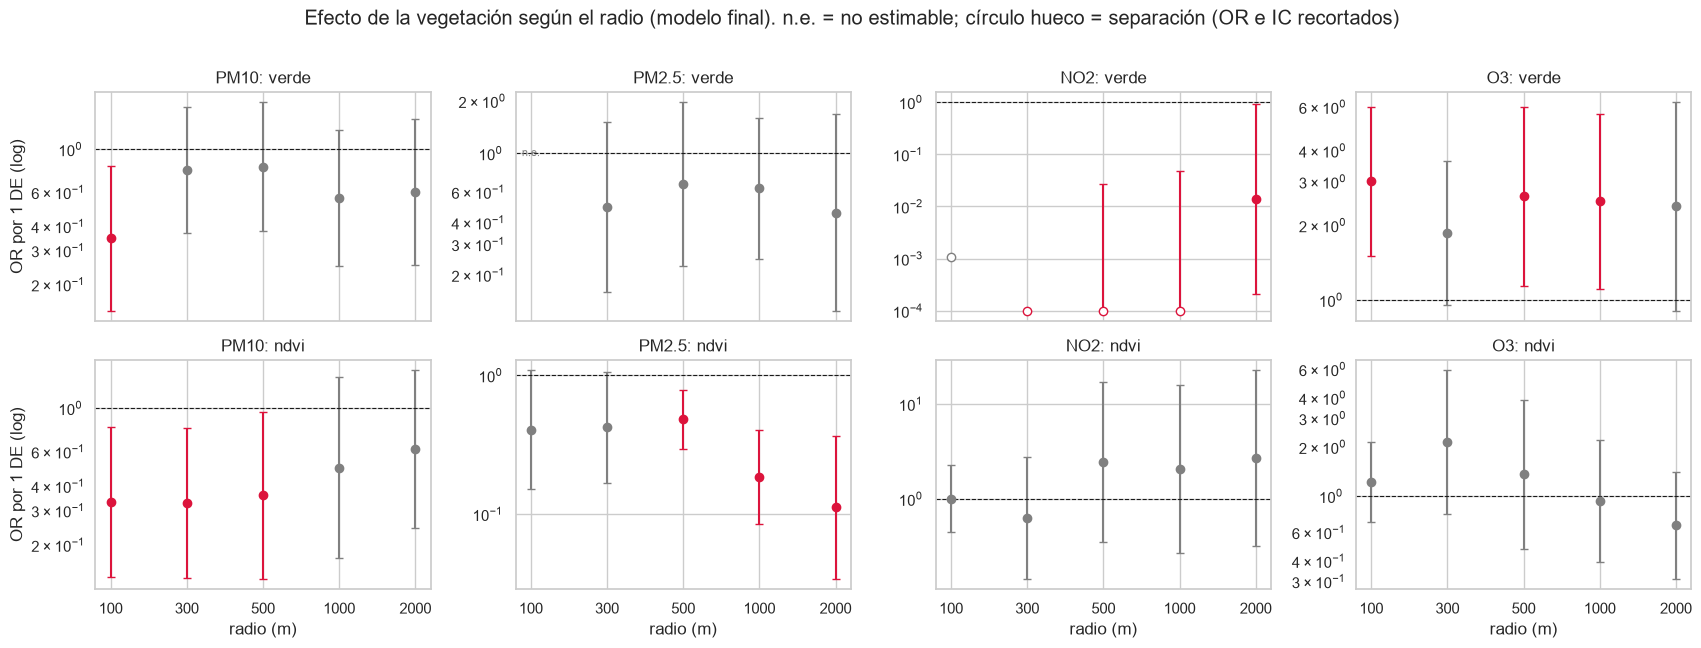

In [39]:
# OR (IC 95 %, cluster) de la vegetación por radio. Rojo = p < 0.05
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.3 * len(CONTAMINANTES), 6.4), sharex=True)
for j, c in enumerate(CONTAMINANTES):
    for i, var in enumerate(["verde", "ndvi"]):
        ax = axes[i, j]
        for k, r in enumerate(RADIOS):
            m = ajustes_radio[(c, r)][1]; v = f"{var}_{r}"
            if v not in m.params.index: ax.text(k, 1, "n.e.", ha="center", va="center", fontsize=8, color="gray"); continue
            ic = np.clip(np.exp(m.conf_int().loc[v]), 1e-4, 1e4); orr = np.clip(np.exp(m.params[v]), 1e-4, 1e4)
            sep = abs(m.params[v]) > 5                                   # separación: OR e IC recortados a [1e-4, 1e4]
            ax.errorbar(k, orr, yerr=[[orr - ic[0]], [ic[1] - orr]], fmt="o", mfc="white" if sep else None,
                        color="crimson" if m.pvalues[v] < .05 else "gray", capsize=3)
        ax.axhline(1, color="k", ls="--", lw=.8); ax.set_yscale("log")
        ax.set_xticks(range(len(RADIOS)), [str(r) for r in RADIOS])
        ax.set_title(f"{c}: {var}"); ax.set_ylabel("OR por 1 DE (log)" if j == 0 else "")
        if i == 1: ax.set_xlabel("radio (m)")
plt.suptitle("Efecto de la vegetación según el radio (modelo final). n.e. = no estimable; círculo hueco = separación (OR e IC recortados)", y=1.01); plt.tight_layout(); plt.show()

## 5.2 Sensibilidad a la especificación (radio principal)
A (sin ubicación) vs. B (final, con ubicación) vs. C (efecto fijo por estación, ridge: solo NDVI, sin p-valores).

In [40]:
def ajustar_ridge(y, X): return LogisticRegression(C=RIDGE_C, max_iter=5000).fit(X.drop(columns="const"), y)

filas = []
for c in CONTAMINANTES:
    for r in RADIOS:
        for spec in ["A", "B"]:
            D = preparar(c, radio=r, spec=spec); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
            orv, pv = or_p(m, f"verde_{r}"); orn, pn = or_p(m, f"ndvi_{r}")
            filas.append({"contaminante": c, "radio": r, "spec": spec, "OR verde": orv, "p verde": pv, "OR ndvi": orn, "p ndvi": pn})
        D = preparar(c, radio=r, spec="C"); rm = ajustar_ridge(D["ytr"], D["Xtr"])
        coef = pd.Series(rm.coef_[0], index=D["Xtr"].columns.drop("const"))
        filas.append({"contaminante": c, "radio": r, "spec": "C (ridge)", "OR ndvi": np.exp(coef[f"ndvi_{r}"])})
comp_spec = pd.DataFrame(filas).set_index(["contaminante", "radio", "spec"])
comp_spec

OR verde  p verde  OR ndvi  p ndvi
contaminante radio spec                                         
PM10         100   A             0.771    0.187    0.364   0.007
                   B             0.347    0.016    0.331   0.014
                   C (ridge)       NaN      NaN    0.605     NaN
             300   A             1.310    0.267    0.343   0.008
                   B             0.779    0.513    0.327   0.013
                   C (ridge)       NaN      NaN    0.676     NaN
             500   A             1.082    0.715    0.575   0.108
                   B             0.811    0.593    0.358   0.040
                   C (ridge)       NaN      NaN    0.792     NaN
             1000  A             0.827    0.376    0.857   0.689
                   B             0.558    0.158    0.497   0.198
                   C (ridge)       NaN      NaN    0.884     NaN
             2000  A             0.908    0.668    0.799   0.576
                   B             0.600    0.249    0.617   0.308
                   C (ridge)       NaN      NaN    0.852     NaN
PM2.5        100   A               NaN      NaN    0.595   0.025
                   B               NaN      NaN    0.405   0.073
                   C (ridge)       NaN      NaN    0.584     NaN
             300   A             0.676    0.036    0.651   0.098
                   B             0.493    0.218    0.421   0.064
                   C (ridge)       NaN      NaN    0.705     NaN
             500   A             0.848    0.441    0.609   0.091
                   B             0.665    0.462    0.482   0.004
                   C (ridge)       NaN      NaN    0.680     NaN
             1000  A             1.079    0.769    0.482   0.065
                   B             0.627    0.328    0.185   0.000
                   C (ridge)       NaN      NaN    0.667     NaN
             2000  A             1.759    0.126    0.301   0.004
                   B             0.456    0.236    0.112   0.000
                   C (ridge)       NaN      NaN    0.603     NaN
NO2          100   A             0.001    0.978    1.060   0.885
                   B             0.001      NaN    1.004   0.993
                   C (ridge)       NaN      NaN    0.841     NaN
             300   A             0.000    0.002    1.062   0.922
                   B             0.000    0.001    0.628   0.535
                   C (ridge)       NaN      NaN    0.710     NaN
             500   A             0.000    0.003    1.354   0.671
                   B             0.000    0.006    2.432   0.368
                   C (ridge)       NaN      NaN    0.664     NaN
             1000  A             0.000    0.004    1.314   0.765
                   B             0.000    0.007    2.068   0.485
                   C (ridge)       NaN      NaN    0.459     NaN
             2000  A             0.017    0.042    1.645   0.593
                   B             0.014    0.046    2.687   0.363
                   C (ridge)       NaN      NaN    0.440     NaN
O3           100   A             1.332    0.084    1.525   0.218
                   B             3.001    0.002    1.217   0.496
                   C (ridge)       NaN      NaN    1.168     NaN
             300   A             0.871    0.556    2.852   0.020
                   B             1.861    0.068    2.145   0.140
                   C (ridge)       NaN      NaN    1.324     NaN
             500   A             1.013    0.954    2.323   0.043
                   B             2.614    0.024    1.356   0.572
                   C (ridge)       NaN      NaN    1.184     NaN
             1000  A             1.087    0.637    1.864   0.053
                   B             2.500    0.027    0.931   0.872
                   C (ridge)       NaN      NaN    1.032     NaN
             2000  A             1.109    0.645    1.548   0.041
                   B             2.380    0.079    0.661   0.282
                   C (ridge)       NaN      NaN    0.990     NaN

## 5.3 ¿Depende el resultado de una sola estación? (leave-one-station-out)
`verde` toma solo un valor por estación y **NE3** tiene mucha más cobertura verde que el resto. Se reajusta el modelo final de cada radio quitando una estación a la vez y se resume cuánto se mueve el OR de `verde`. (En 100 m, quitar NE3 deja `verde_100` constante: ese ajuste no estima `verde`.)

In [41]:
filas = []
for c in CONTAMINANTES:
    for r in RADIOS:
        D, m_full = ajustes_radio[(c, r)]; v = f"verde_{r}"
        if v not in m_full.params.index: continue
        for e in sorted(D["dtr"].estacion.unique()):
            k = (D["dtr"].estacion != e).values
            X = D["Xtr"][k]; X = X.loc[:, (X.std() > 0) | (X.columns == "const")]
            try:
                m = ajustar_sm(D["ytr"][k], X, D["dtr"].loc[k, "estacion"]); orv, pv = or_p(m, v)
            except Exception:
                orv, pv = np.nan, np.nan
            filas.append({"contaminante": c, "radio": r, "sin estación": e, "OR verde": orv, "p verde": pv, "OR completo": np.exp(m_full.params[v])})
loo = pd.DataFrame(filas)
def resumen_loo(g):
    dist = (np.log(g["OR verde"]) - np.log(g["OR completo"])).abs()
    e = g.loc[dist.idxmax()] if dist.notna().any() else None
    return pd.Series({"OR completo": g["OR completo"].iloc[0], "OR mín": g["OR verde"].min(), "OR máx": g["OR verde"].max(),
                      "ajustes con p<0.05": int((g["p verde"] < .05).sum()), "ajustes": int(g["OR verde"].notna().sum()),
                      "estación más influyente": e["sin estación"] if e is not None else "", "OR sin ella": e["OR verde"] if e is not None else np.nan})
loo.groupby(["contaminante", "radio"]).apply(resumen_loo)

OR completo  OR mín    OR máx  ajustes con p<0.05  \
contaminante radio                                                      
NO2          100          0.001   0.001     0.005                   0   
             300          0.000   0.000     0.000                  13   
             500          0.000   0.000     0.002                  14   
             1000         0.000   0.000     0.007                  13   
             2000         0.014   0.001     0.198                   7   
O3           100          3.001   2.551     3.687                  14   
             300          1.861   0.059     2.580                   2   
             500          2.614   1.146     3.410                  11   
             1000         2.500   0.472     3.140                  10   
             2000         2.380   0.599     3.246                   1   
PM10         100          0.347   0.248     0.480                  12   
             300          0.779   0.536 13085.253                   1   
             500          0.811   0.483   212.933                   1   
             1000         0.558   0.341     4.260                   0   
             2000         0.600   0.413     2.606                   0   
PM2.5        300          0.493   0.001     1.031                   2   
             500          0.665   0.261     7.533                   1   
             1000         0.627   0.389     2.517                   0   
             2000         0.456   0.257     1.723                   2   

                    ajustes estación más influyente  OR sin ella  
contaminante radio                                                
NO2          100         14                     NO2        0.005  
             300         15                    NTE2        0.000  
             500         15                     SE2        0.000  
             1000        15                      NE        0.000  
             2000        15                    NTE2        0.198  
O3           100         14                      NE        3.687  
             300         15                     NE3        0.059  
             500         15                     NE3        1.146  
             1000        15                     NE3        0.472  
             2000        15                     NE3        0.599  
PM10         100         15                      SE        0.248  
             300         15                     NE3    13085.253  
             500         15                     NE3      212.933  
             1000        15                     NE3        4.260  
             2000        15                     NE3        2.606  
PM2.5        300         11                     SE3        0.001  
             500         11                     NO2        7.533  
             1000        11                     NO2        2.517  
             2000        11                     NO2        1.723

## 5.4 Prueba a nivel estación (la más conservadora)
La cobertura verde cambia solo **entre** estaciones, así que la información real para estimar su efecto son 15 estaciones (11 en PM2.5), no ~200 meses. Aquí se reduce cada estación a un número —el **% de meses altos** en los 24 meses— y se correlaciona (Spearman) con su cobertura verde y su NDVI medio en cada radio. No controla meteorología ni ubicación, pero no depende de supuestos del logit ni de la separación, y respeta que la unidad de comparación es la estación.

variable           NDVI medio              verde             
                            p rho Spearman     p rho Spearman
contaminante radio                                           
NO2          100        0.368       -0.250 0.210       -0.343
             300        0.235       -0.326 0.076       -0.472
             500        0.204       -0.348 0.109       -0.430
             1000       0.035       -0.546 0.095       -0.447
             2000       0.017       -0.605 0.061       -0.494
O3           100        0.884       -0.041 0.314       -0.279
             300        0.955        0.016 0.141       -0.399
             500        0.368       -0.251 0.195       -0.354
             1000       0.611       -0.143 0.694       -0.111
             2000       0.579       -0.156 0.656       -0.125
PM10         100        0.025       -0.576 0.105       -0.435
             300        0.086       -0.457 0.584        0.154
             500        0.698       -0.109 0.324        0.274
             1000       0.939        0.022 0.712        0.104
             2000       0.799       -0.072 0.736       -0.095
PM2.5        100        0.179       -0.437   NaN          NaN
             300        0.926        0.032 0.401       -0.282
             500        0.863       -0.059 0.241       -0.386
             1000       0.669       -0.146 0.199       -0.419
             2000       0.325       -0.328 0.501       -0.228

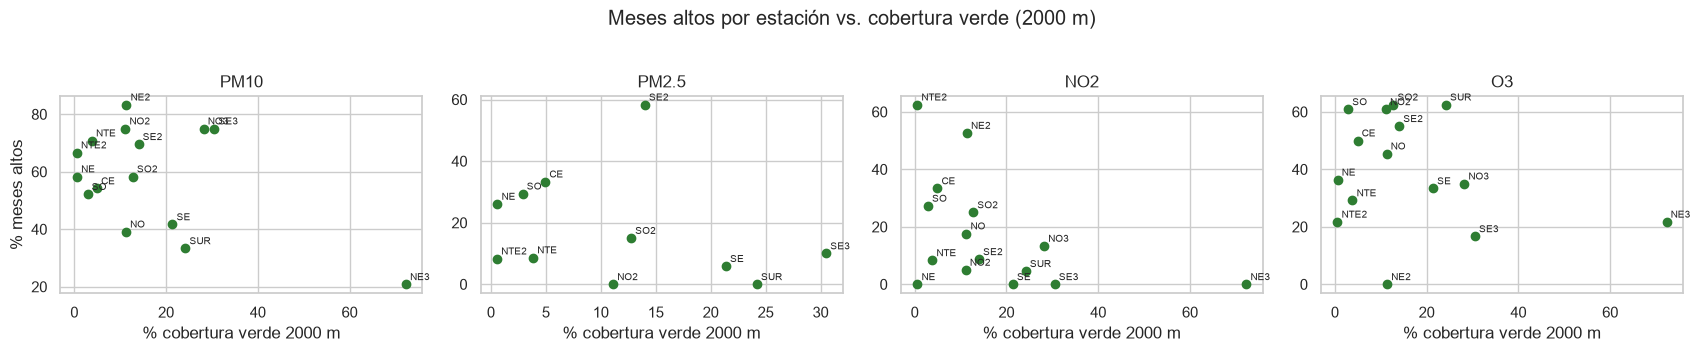

In [42]:
pct_alto = pd.DataFrame({c: base.groupby("estacion")[c].apply(lambda s: 100 * (s.dropna() > UMBRALES[c]).mean() if s.notna().sum() >= 6 else np.nan)
                         for c in CONTAMINANTES})
filas = []
for c in CONTAMINANTES:
    for r in RADIOS:
        for var, col in [("verde", f"verde_{r}"), ("NDVI medio", f"ndvi_{r}_medio")]:
            t = pd.concat([pct_alto[c], fijos[col]], axis=1).dropna()
            rho, p = stats.spearmanr(t.iloc[:, 0], t.iloc[:, 1]) if t.iloc[:, 1].nunique() > 1 else (np.nan, np.nan)
            filas.append({"contaminante": c, "radio": r, "variable": var, "n estaciones": len(t), "rho Spearman": rho, "p": p})
estacion_nivel = pd.DataFrame(filas).pivot_table(index=["contaminante", "radio"], columns="variable", values=["rho Spearman", "p"]).swaplevel(axis=1).sort_index(axis=1)
display(estacion_nivel)

fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(4.3 * len(CONTAMINANTES), 3.4), sharey=False)
for ax, c in zip(axes, CONTAMINANTES):
    t = pd.concat([pct_alto[c], fijos[f"verde_{RADIO}"]], axis=1).dropna()
    ax.scatter(t[f"verde_{RADIO}"], t[c], color="#2E7D32")
    for e, rr in t.iterrows(): ax.annotate(e, (rr[f"verde_{RADIO}"], rr[c]), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set_xlabel(f"% cobertura verde {RADIO} m"); ax.set_ylabel("% meses altos" if c == CONTAMINANTES[0] else ""); ax.set_title(c)
plt.suptitle(f"Meses altos por estación vs. cobertura verde ({RADIO} m)", y=1.03); plt.tight_layout(); plt.show()

# Validación de supuestos
Diagnósticos del **radio principal** sobre el entrenamiento, para el modelo con vegetación (y, donde aplica, el modelo sin vegetación).

### Linealidad del logit
Predictores que cambian en el tiempo, divididos en 5 quintiles; logit empírico vs. promedio del predictor (debería ser aproximadamente recto). `verde`, `lat` y `elev` toman solo un valor por estación y no aplican.

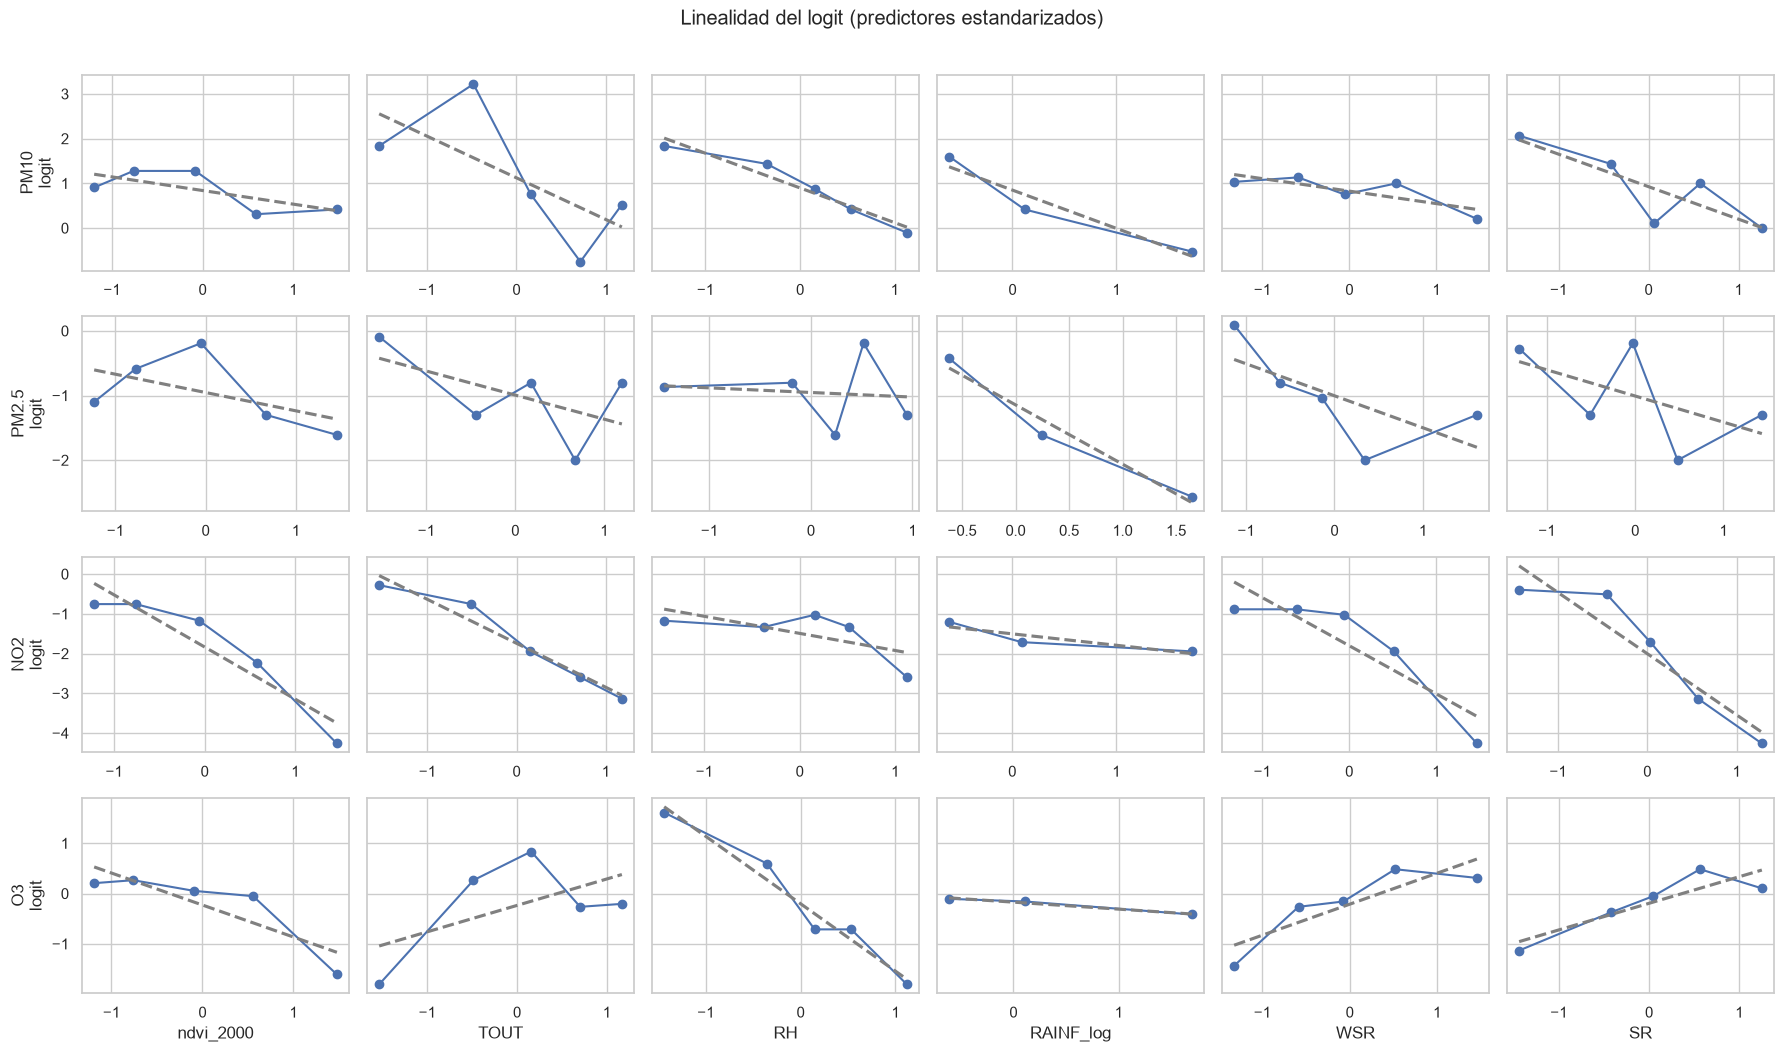

In [43]:
def logit_emp(y, x, bins=5):
    g = pd.DataFrame({"x": x, "y": y}); g["b"] = pd.qcut(g["x"], bins, duplicates="drop")
    t = g.groupby("b", observed=True).agg(x=("x", "mean"), s=("y", "sum"), n=("y", "size"))
    t["logit"] = np.log((t.s + 0.5) / (t.n - t.s + 0.5)); return t

VARS_TIEMPO = [f"ndvi_{RADIO}"] + METEO
fig, axes = plt.subplots(len(CONTAMINANTES), len(VARS_TIEMPO), figsize=(3 * len(VARS_TIEMPO), 2.6 * len(CONTAMINANTES)), sharey="row")
for i, c in enumerate(CONTAMINANTES):
    D = datos[c]
    for j, vv in enumerate(VARS_TIEMPO):
        t = logit_emp(D["ytr"], D["Xtr"][vv]); ax = axes[i, j]
        ax.plot(t.x, t.logit, "o-")
        sns.regplot(x=t.x, y=t.logit, scatter=False, ci=None, color="gray", line_kws={"ls": "--"}, ax=ax)
        ax.set_xlabel(vv if i == len(CONTAMINANTES) - 1 else ""); ax.set_ylabel(f"{c}\nlogit" if j == 0 else "")
plt.suptitle("Linealidad del logit (predictores estandarizados)", y=1.01); plt.tight_layout(); plt.show()

### Observaciones influyentes
Distancia de Cook (referencia $4/n$).

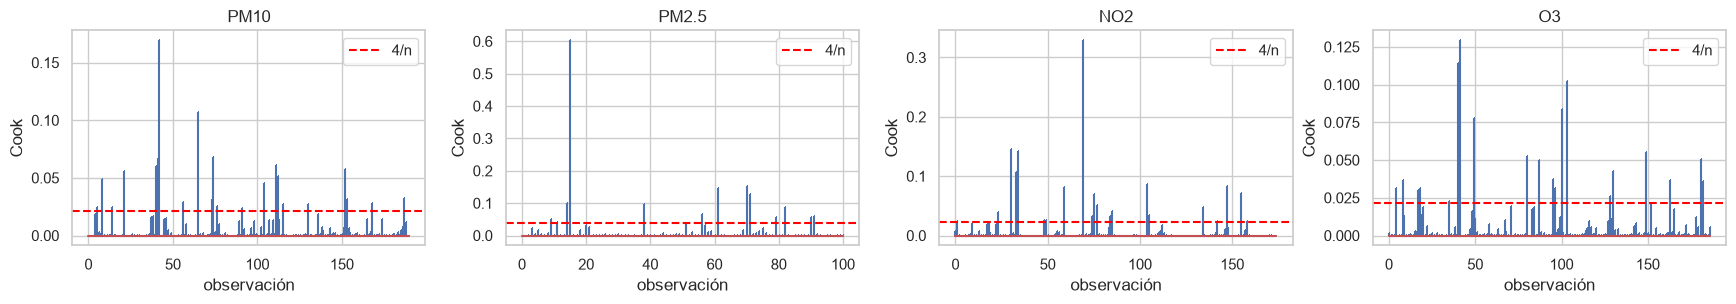

,estacion,fecha_mes,PM10,cook,PM2.5,NO2,O3
contaminante,,,,,,,
PM10,NE3,2024-05,54.111,0.169,NaN,NaN,NaN
PM10,NO2,2024-06,51.082,0.107,NaN,NaN,NaN
PM10,NO3,2024-07,53.647,0.068,NaN,NaN,NaN
PM10,NE3,2024-04,45.964,0.067,NaN,NaN,NaN
PM10,SE,2024-12,47.713,0.061,NaN,NaN,NaN
PM2.5,NO2,2024-04,NaN,0.603,12.096,NaN,NaN
PM2.5,SE3,2025-03,NaN,0.151,26.290,NaN,NaN
PM2.5,SE3,2024-05,NaN,0.146,31.281,NaN,NaN
PM2.5,SE3,2025-04,NaN,0.128,21.364,NaN,NaN


In [44]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(4.4 * len(CONTAMINANTES), 3.2))
influyentes = {}
for ax, c in zip(axes, CONTAMINANTES):
    D = datos[c]; glm = sm.GLM(D["ytr"], D["Xtr"], family=sm.families.Binomial()).fit()
    cook = pd.Series(glm.get_influence().cooks_distance[0], index=D["dtr"].index)
    ax.stem(range(len(cook)), cook.values, markerfmt=","); ax.axhline(4 / len(cook), color="red", ls="--", label="4/n")
    ax.set_title(c); ax.set_xlabel("observación"); ax.set_ylabel("Cook"); ax.legend()
    influyentes[c] = D["dtr"].loc[cook.nlargest(5).index, ["estacion", "fecha_mes", c]].assign(cook=cook.nlargest(5))
plt.tight_layout(); plt.show()
pd.concat(influyentes, names=["contaminante"]).droplevel(1)

### Bondad de ajuste (entrenamiento)
Razón de verosimilitud vs. solo constante, Hosmer-Lemeshow ($H_0$: ajusta bien) y McFadden R², para los modelos con y sin vegetación.

In [45]:
def hosmer_lemeshow(y, p, g=10):
    t = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)}); t["grupo"] = pd.qcut(t["p"], g, duplicates="drop")
    r = t.groupby("grupo", observed=True).agg(obs=("y", "sum"), esp=("p", "sum"), n=("y", "size"))
    chi2 = (((r.obs - r.esp) ** 2) / (r.esp * (1 - r.esp / r.n))).sum(); gl = len(r) - 2
    return chi2, gl, stats.chi2.sf(chi2, gl)

gof = []
for c in CONTAMINANTES:
    for nombre, D, m in [(f"con vegetación ({RADIO} m)", datos[c], modelos[c]), ("sin vegetación", datos_sv[c], modelos_sv[c])]:
        hl, gl, p_hl = hosmer_lemeshow(D["ytr"], m.predict(D["Xtr"]))
        gof.append({"contaminante": c, "modelo": nombre, "McFadden R2": m.prsquared, "LR chi2": m.llr, "p (LR)": m.llr_pvalue,
                    "HL chi2": hl, "HL gl": gl, "p (HL)": p_hl})
pd.DataFrame(gof).set_index(["contaminante", "modelo"])

McFadden R2  LR chi2  p (LR)  HL chi2  \
contaminante modelo                                                           
PM10         con vegetación (2000 m)        0.526  123.396   0.000    3.061   
             sin vegetación                 0.496  116.324   0.000   11.584   
PM2.5        con vegetación (2000 m)        0.422   50.315   0.000    2.612   
             sin vegetación                 0.314   37.462   0.000   15.899   
NO2          con vegetación (2000 m)        0.595  100.808   0.000    1.423   
             sin vegetación                 0.541   91.688   0.000    4.509   
O3           con vegetación (2000 m)        0.498  128.449   0.000    5.309   
             sin vegetación                 0.484  124.677   0.000    7.700   

                                      HL gl  p (HL)  
contaminante modelo                                  
PM10         con vegetación (2000 m)      8   0.930  
             sin vegetación               8   0.171  
PM2.5        con vegetación (2000 m)      8   0.956  
             sin vegetación               8   0.044  
NO2          con vegetación (2000 m)      8   0.994  
             sin vegetación               8   0.809  
O3           con vegetación (2000 m)      8   0.724  
             sin vegetación               8   0.463

### Independencia: residuos por estación

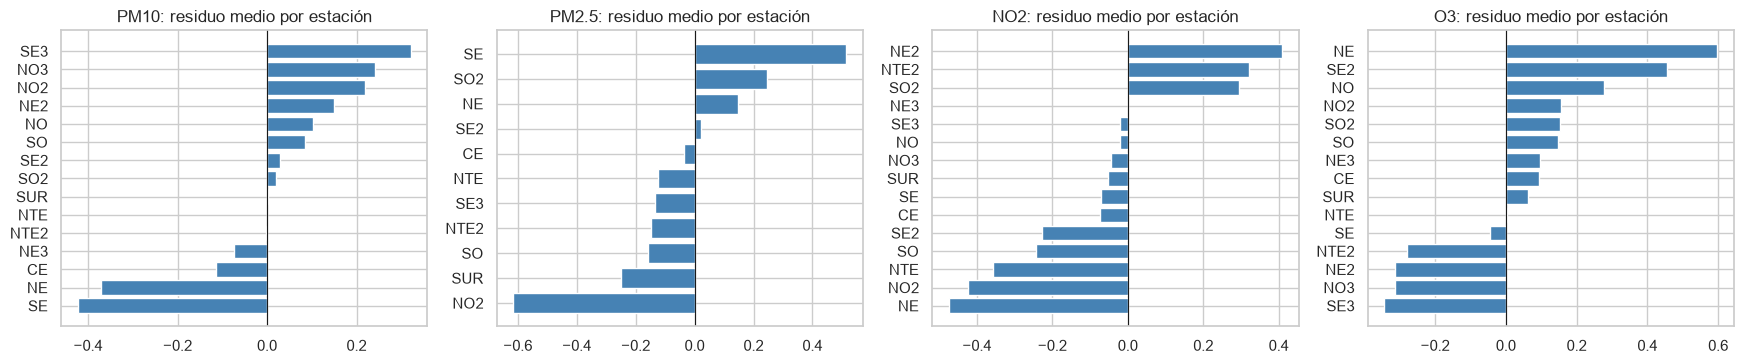

In [46]:
fig, axes = plt.subplots(1, len(CONTAMINANTES), figsize=(4.4 * len(CONTAMINANTES), 3.8))
for ax, c in zip(axes, CONTAMINANTES):
    D = datos[c]; p = modelos[c].predict(D["Xtr"])
    res = ((D["ytr"] - p) / np.sqrt(p * (1 - p))).groupby(D["dtr"]["estacion"]).mean().sort_values()
    ax.barh(res.index, res.values, color="steelblue"); ax.axvline(0, color="k", lw=0.8); ax.set_title(f"{c}: residuo medio por estación")
plt.tight_layout(); plt.show()

### Autocorrelación temporal de los residuos
Residuos de Pearson, rezago 1 (meses consecutivos de la misma estación), por especificación sucesiva. Respecto a v3 se quitó el paso "+ O3".

In [47]:
def ac_resid(d, r):
    t = d[["estacion", "t"]].assign(r=np.asarray(r)); t["r_prev"] = t.groupby("estacion")["r"].shift(1)
    x = t[t.groupby("estacion")["t"].diff() == 1][["r", "r_prev"]].dropna()
    rho, p = stats.pearsonr(x["r"], x["r_prev"]); return rho, p, len(x)

specs = {"1. Meteorología + vegetación":        dict(spec="A", anio=False, rezago=False),
         "2. + año 2025":                       dict(spec="A", anio=True,  rezago=False),
         "3. + y(t-1)":                         dict(spec="A", anio=True,  rezago=True),
         "4. + ubicación [final, con veg.]":    dict(spec="B"),
         "5. final sin vegetación":             dict(spec="B", veg=False)}
filas = []
for c in CONTAMINANTES:
    for nombre, kw in specs.items():
        D = preparar(c, **kw); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
        p = m.predict(D["Xtr"]); r = (D["ytr"] - p) / np.sqrt(p * (1 - p)); rho, pv, n = ac_resid(D["dtr"], r)
        orv, pvv = or_p(m, f"verde_{RADIO}")
        filas.append({"contaminante": c, "especificación": nombre, "n": int(m.nobs), "AC residuos (rezago 1)": rho, "p (AC)": pv,
                      "McFadden R2": m.prsquared, f"OR verde_{RADIO}": orv, f"p verde_{RADIO}": pvv})
pd.DataFrame(filas).set_index(["contaminante", "especificación"])

n  AC residuos (rezago 1)  \
contaminante especificación                                                  
PM10         1. Meteorología + vegetación      203                   0.305   
             2. + año 2025                     203                   0.211   
             3. + y(t-1)                       191                   0.019   
             4. + ubicación [final, con veg.]  191                   0.003   
             5. final sin vegetación           191                  -0.010   
PM2.5        1. Meteorología + vegetación      120                   0.170   
             2. + año 2025                     120                   0.128   
             3. + y(t-1)                       101                  -0.059   
             4. + ubicación [final, con veg.]  101                  -0.057   
             5. final sin vegetación           101                  -0.112   
NO2          1. Meteorología + vegetación      189                   0.430   
             2. + año 2025                     189                   0.449   
             3. + y(t-1)                       175                  -0.074   
             4. + ubicación [final, con veg.]  175                  -0.131   
             5. final sin vegetación           175                  -0.033   
O3           1. Meteorología + vegetación      201                   0.367   
             2. + año 2025                     201                   0.369   
             3. + y(t-1)                       187                  -0.036   
             4. + ubicación [final, con veg.]  187                  -0.057   
             5. final sin vegetación           187                  -0.040   

                                               p (AC)  McFadden R2  \
contaminante especificación                                          
PM10         1. Meteorología + vegetación       0.000        0.270   
             2. + año 2025                      0.005        0.453   
             3. + y(t-1)                        0.809        0.474   
             4. + ubicación [final, con veg.]   0.966        0.526   
             5. final sin vegetación            0.896        0.496   
PM2.5        1. Meteorología + vegetación       0.103        0.243   
             2. + año 2025                      0.221        0.249   
             3. + y(t-1)                        0.603        0.337   
             4. + ubicación [final, con veg.]   0.611        0.422   
             5. final sin vegetación            0.318        0.314   
NO2          1. Meteorología + vegetación       0.000        0.462   
             2. + año 2025                      0.000        0.464   
             3. + y(t-1)                        0.372        0.584   
             4. + ubicación [final, con veg.]   0.114        0.595   
             5. final sin vegetación            0.688        0.541   
O3           1. Meteorología + vegetación       0.000        0.309   
             2. + año 2025                      0.000        0.309   
             3. + y(t-1)                        0.659        0.475   
             4. + ubicación [final, con veg.]   0.477        0.498   
             5. final sin vegetación            0.623        0.484   

                                               OR verde_2000  p verde_2000  
contaminante especificación                                                 
PM10         1. Meteorología + vegetación              0.532         0.001  
             2. + año 2025                             0.825         0.367  
             3. + y(t-1)                               0.908         0.668  
             4. + ubicación [final, con veg.]          0.600         0.249  
             5. final sin vegetación                     NaN           NaN  
PM2.5        1. Meteorología + vegetación              1.896         0.156  
             2. + año 2025                             1.651         0.352  
             3. + y(t-1)                               1.759         0.126  
             4. + ubi

### Autocorrelación espacial (I de Moran por estación)
Pesos $w_{ij}=1/d_{ij}$ (km). Nivel medio del contaminante y residuo medio por estación de los modelos con y sin vegetación. p de permutación (9 999). Con 11–15 estaciones la prueba tiene poca potencia.

In [48]:
def haversine_km(lat1, lon1, lat2, lon2):
    p = np.pi / 180; a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

def moran(valores, nperm=9999, seed=0):
    v = valores.dropna(); est = v.index
    lat, lon = UBIC.loc[est, "lat"].values, UBIC.loc[est, "lon"].values
    Dm = haversine_km(lat[:, None], lon[:, None], lat[None, :], lon[None, :])
    W = np.divide(1, Dm, out=np.zeros_like(Dm), where=Dm > 0)
    def I(x): z = x - x.mean(); return (len(x) / W.sum()) * (z @ W @ z) / (z @ z)
    obs = I(v.values); rng = np.random.default_rng(seed)
    perm = np.array([I(rng.permutation(v.values)) for _ in range(nperm)])
    return obs, -1 / (len(v) - 1), (np.sum(np.abs(perm - perm.mean()) >= abs(obs - perm.mean())) + 1) / (nperm + 1), len(v)

def resid_estacion(D, m):
    p = m.predict(D["Xtr"]); return ((D["ytr"] - p) / np.sqrt(p * (1 - p))).groupby(D["dtr"]["estacion"]).mean()

filas = []
for c in CONTAMINANTES:
    series = {"nivel medio del contaminante": base.groupby("estacion")[c].mean(),
              f"residuo con vegetación ({RADIO} m)": resid_estacion(datos[c], modelos[c]),
              "residuo sin vegetación": resid_estacion(datos_sv[c], modelos_sv[c])}
    for nombre, s in series.items():
        I, EI, p, n = moran(s); filas.append({"contaminante": c, "variable": nombre, "n estaciones": n, "I de Moran": I, "E[I]": EI, "p (permutación)": p})
pd.DataFrame(filas).set_index(["contaminante", "variable"])

n estaciones  I de Moran   E[I]  \
contaminante variable                                                           
PM10         nivel medio del contaminante               15      -0.080 -0.071   
             residuo con vegetación (2000 m)            15       0.002 -0.071   
             residuo sin vegetación                     15      -0.057 -0.071   
PM2.5        nivel medio del contaminante               11      -0.079 -0.100   
             residuo con vegetación (2000 m)            11      -0.110 -0.100   
             residuo sin vegetación                     11      -0.064 -0.100   
NO2          nivel medio del contaminante               15      -0.019 -0.071   
             residuo con vegetación (2000 m)            15      -0.162 -0.071   
             residuo sin vegetación                     15      -0.094 -0.071   
O3           nivel medio del contaminante               15      -0.033 -0.071   
             residuo con vegetación (2000 m)            15      -0.171 -0.071   
             residuo sin vegetación                     15      -0.141 -0.071   

                                              p (permutación)  
contaminante variable                                          
PM10         nivel medio del contaminante               0.878  
             residuo con vegetación (2000 m)            0.130  
             residuo sin vegetación                     0.776  
PM2.5        nivel medio del contaminante               0.787  
             residuo con vegetación (2000 m)            0.876  
             residuo sin vegetación                     0.617  
NO2          nivel medio del contaminante               0.266  
             residuo con vegetación (2000 m)            0.064  
             residuo sin vegetación                     0.625  
O3           nivel medio del contaminante               0.444  
             residuo con vegetación (2000 m)            0.044  
             residuo sin vegetación                     0.161

# Eficiencia del modelo: con vs. sin vegetación (validación temporal)
Todas las estaciones están en entrenamiento y prueba; lo que se separa es el tiempo.
1. **Corte único:** entrena 2024-01 a 2025-06, predice 2025-07 a 2025-12.
2. **Walk-forward:** entrena con los primeros 12 meses y predice el 13; luego con 13 predice el 14, etc., hasta el 24 (z-score recalculado en cada paso solo con el pasado).

Se comparan el modelo **con vegetación** en cada radio, el modelo **sin vegetación**, y dos referencias: **persistencia** (el mes será igual al anterior) y **mayoría del entrenamiento**. Umbral de clasificación 0.5. Además de exactitud, precisión, sensibilidad y F1 (que dependen del corte 0.5), se reportan **AUC**, **Brier** y **log-loss** (miden la calidad de las probabilidades; en Brier y log-loss, menor = mejor).

In [49]:
def metricas(y, p=None, pred=None):
    y = np.asarray(y)
    pred = (np.asarray(p) >= 0.5).astype(int) if pred is None else np.asarray(pred).astype(int)
    out = {"n": len(y), "eventos": int(y.sum()), "exactitud": accuracy_score(y, pred),
           "AUC": roc_auc_score(y, p) if (p is not None and len(np.unique(y)) > 1) else np.nan,
           "precisión": precision_score(y, pred, zero_division=0), "sensibilidad": recall_score(y, pred, zero_division=0),
           "F1": f1_score(y, pred, zero_division=0)}
    if p is not None: out.update({"Brier": brier_score_loss(y, p), "log-loss": log_loss(y, np.clip(p, 1e-6, 1 - 1e-6), labels=[0, 1])})
    return out

MODELOS = [(f"con vegetación {r} m", dict(radio=r, veg=True)) for r in RADIOS] + [("sin vegetación", dict(veg=False))]
def predecir(c, corte, **kw):
    D = preparar(c, corte=corte, **kw); m = ajustar_sm(D["ytr"], D["Xtr"], D["dtr"]["estacion"])
    return D, np.asarray(m.predict(D["Xte"]))

filas, corte_pred = [], {}
for c in CONTAMINANTES:
    for nombre, kw in MODELOS:
        D, p = predecir(c, T_CORTE, **kw); corte_pred[(c, nombre)] = (D, p)
        filas.append({"contaminante": c, "modelo": nombre, **metricas(D["yte"], p)})
    D = corte_pred[(c, "sin vegetación")][0]
    filas.append({"contaminante": c, "modelo": "referencia: persistencia", **metricas(D["yte"], pred=D["dte"]["y_rez"].values)})
    filas.append({"contaminante": c, "modelo": "referencia: mayoría entren.", **metricas(D["yte"], pred=np.full(len(D["yte"]), int(D["ytr"].mean() >= .5)))})
res_corte = pd.DataFrame(filas).set_index(["contaminante", "modelo"])
print(f"Corte único: entrena antes de {FECHA_CORTE}, prueba desde {FECHA_CORTE}")
res_corte

Corte único: entrena antes de 2025-07, prueba desde 2025-07


n  eventos  exactitud   AUC  \
contaminante modelo                                                      
PM10         con vegetación 100 m         64       15      0.844 0.946   
             con vegetación 300 m         64       15      0.875 0.952   
             con vegetación 500 m         64       15      0.859 0.941   
             con vegetación 1000 m        64       15      0.875 0.936   
             con vegetación 2000 m        64       15      0.859 0.936   
             sin vegetación               64       15      0.875 0.937   
             referencia: persistencia     64       15      0.844   NaN   
             referencia: mayoría entren.  64       15      0.234   NaN   
PM2.5        con vegetación 100 m         29        1      0.862 1.000   
             con vegetación 300 m         29        1      0.862 0.964   
             con vegetación 500 m         29        1      0.862 0.964   
             con vegetación 1000 m        29        1      0.931 0.929   
             con vegetación 2000 m        29        1      0.862 0.929   
             sin vegetación               29        1      0.966 1.000   
             referencia: persistencia     29        1      1.000   NaN   
             referencia: mayoría entren.  29        1      0.966   NaN   
NO2          con vegetación 100 m         56       11      0.911 0.976   
             con vegetación 300 m         56       11      0.946 0.909   
             con vegetación 500 m         56       11      0.893 0.923   
             con vegetación 1000 m        56       11      0.911 0.848   
             con vegetación 2000 m        56       11      0.893 0.943   
             sin vegetación               56       11      0.911 0.970   
             referencia: persistencia     56       11      0.911   NaN   
             referencia: mayoría entren.  56       11      0.804   NaN   
O3           con vegetación 100 m         56       20      0.661 0.732   
             con vegetación 300 m         56       20      0.643 0.729   
             con vegetación 500 m         56       20      0.679 0.737   
             con vegetación 1000 m        56       20      0.679 0.749   
             con vegetación 2000 m        56       20      0.661 0.754   
             sin vegetación               56       20      0.696 0.771   
             referencia: persistencia     56       20      0.804   NaN   
             referencia: mayoría entren.  56       20      0.643   NaN   

                                          precisión  sensibilidad    F1  \
contaminante modelo                                                       
PM10         con vegetación 100 m             0.667         0.667 0.667   
             con vegetación 300 m             0.769         0.667 0.714   
             con vegetación 500 m             0.750         0.600 0.667   
             con vegetación 1000 m            0.818         0.600 0.692   
             con vegetación 2000 m            0.800         0.533 0.640   
             sin vegetación                   0.889         0.533 0.667   
             referencia: persistencia         0.778         0.467 0.583   
             referencia: mayoría entren.      0.234         1.000 0.380   
PM2.5        con vegetación 100 m             0.200         1.000 0.333   
             con vegetación 300 m             0.200         1.000 0.333   
             con vegetación 500 m             0.200         1.000 0.333   
             con vegetación 1000 m            0.333         1.000 0.500   
             con vegetación 2000 m            0.200         1.000 0.333   
             sin vegetación                   0.500         1.000 0.667   
             referencia: persistencia         1.000         1.000 1.000   
             referencia: mayoría entren.      0.000         0.000 0.000   
NO2          con vegetación 100 m             0.875         0.636 0.737   
             con vegetación 300 m             0.833         0.909 0.870   
             con vegetació

In [50]:
filas, wf_pred = [], {}
for c in CONTAMINANTES:
    acum = {n: [] for n, _ in MODELOS}
    for k in range(INICIO_WALK_FORWARD, 24):
        for nombre, kw in MODELOS:
            D, p = predecir(c, k, **kw); sel = (D["dte"]["t"] == k).values
            acum[nombre].append(pd.DataFrame({"y": D["yte"].values[sel], "proba": p[sel], "t": k, "estacion": D["dte"]["estacion"].values[sel],
                                              "y_rez": D["dte"]["y_rez"].values[sel], "mayoria": int(D["ytr"].mean() >= .5)},
                                             index=D["dte"].index[sel]))
    for nombre, _ in MODELOS:
        r = pd.concat(acum[nombre]); wf_pred[(c, nombre)] = r
        filas.append({"contaminante": c, "modelo": nombre, **metricas(r.y, r.proba.values)})
    r = wf_pred[(c, "sin vegetación")]
    filas.append({"contaminante": c, "modelo": "referencia: persistencia", **metricas(r.y, pred=r.y_rez.values)})
    filas.append({"contaminante": c, "modelo": "referencia: mayoría entren.", **metricas(r.y, pred=r.mayoria.values)})
res_wf = pd.DataFrame(filas).set_index(["contaminante", "modelo"])
print(f"Walk-forward: {INICIO_WALK_FORWARD} meses iniciales, se predice un mes a la vez hasta el mes 24")
res_wf

Walk-forward: 12 meses iniciales, se predice un mes a la vez hasta el mes 24


n  eventos  exactitud   AUC  \
contaminante modelo                                                       
PM10         con vegetación 100 m         129       50      0.752 0.890   
             con vegetación 300 m         129       50      0.806 0.885   
             con vegetación 500 m         129       50      0.798 0.877   
             con vegetación 1000 m        129       50      0.791 0.875   
             con vegetación 2000 m        129       50      0.767 0.872   
             sin vegetación               129       50      0.798 0.868   
             referencia: persistencia     129       50      0.814   NaN   
             referencia: mayoría entren.  129       50      0.388   NaN   
PM2.5        con vegetación 100 m          63       13      0.810 0.785   
             con vegetación 300 m          63       13      0.794 0.758   
             con vegetación 500 m          63       13      0.810 0.734   
             con vegetación 1000 m         63       13      0.794 0.766   
             con vegetación 2000 m         63       13      0.794 0.809   
             sin vegetación                63       13      0.841 0.785   
             referencia: persistencia      63       13      0.857   NaN   
             referencia: mayoría entren.   63       13      0.794   NaN   
NO2          con vegetación 100 m         109       22      0.908 0.941   
             con vegetación 300 m         109       22      0.899 0.948   
             con vegetación 500 m         109       22      0.908 0.943   
             con vegetación 1000 m        109       22      0.908 0.931   
             con vegetación 2000 m        109       22      0.927 0.935   
             sin vegetación               109       22      0.908 0.932   
             referencia: persistencia     109       22      0.890   NaN   
             referencia: mayoría entren.  109       22      0.798   NaN   
O3           con vegetación 100 m         119       50      0.723 0.822   
             con vegetación 300 m         119       50      0.723 0.824   
             con vegetación 500 m         119       50      0.739 0.821   
             con vegetación 1000 m        119       50      0.706 0.824   
             con vegetación 2000 m        119       50      0.714 0.820   
             sin vegetación               119       50      0.739 0.823   
             referencia: persistencia     119       50      0.782   NaN   
             referencia: mayoría entren.  119       50      0.580   NaN   

                                          precisión  sensibilidad    F1  \
contaminante modelo                                                       
PM10         con vegetación 100 m             0.625         0.900 0.738   
             con vegetación 300 m             0.692         0.900 0.783   
             con vegetación 500 m             0.688         0.880 0.772   
             con vegetación 1000 m            0.677         0.880 0.765   
             con vegetación 2000 m            0.656         0.840 0.737   
             sin vegetación                   0.700         0.840 0.764   
             referencia: persistencia         0.750         0.780 0.765   
             referencia: mayoría entren.      0.388         1.000 0.559   
PM2.5        con vegetación 100 m             0.538         0.538 0.538   
             con vegetación 300 m             0.500         0.615 0.552   
             con vegetación 500 m             0.538         0.538 0.538   
             con vegetación 1000 m            0.500         0.615 0.552   
             con vegetación 2000 m            0.500         0.692 0.581   
             sin vegetación                   0.615         0.615 0.615   
             referencia: persistencia         0.625         0.769 0.690   
             referencia: mayoría entren.      0.000         0.000 0.000   
NO2          con vegetación 100 m             0.833         0.682 0.750   
             con vegetación 300 m             0.762         0.727 0.

### ¿La vegetación mejora la predicción? Diferencia de AUC con bootstrap
Diferencia de AUC walk-forward (con vegetación − sin vegetación) sobre las **mismas predicciones**, con IC 95 % por bootstrap **por estación** (se remuestrean estaciones completas, respetando la dependencia dentro de cada una). Si el intervalo incluye 0, la vegetación no mejora la discriminación de forma detectable.

In [51]:
def boot_dauc(a, b, nboot=N_BOOT, seed=1):
    assert a.index.equals(b.index)
    y, pa, pb, g = a.y.values, a.proba.values, b.proba.values, a.estacion.values
    grupos = np.unique(g); idx = {e: np.where(g == e)[0] for e in grupos}; rng = np.random.default_rng(seed); difs = []
    for _ in range(nboot):
        ii = np.concatenate([idx[e] for e in rng.choice(grupos, len(grupos))])
        if len(np.unique(y[ii])) < 2: continue
        difs.append(roc_auc_score(y[ii], pa[ii]) - roc_auc_score(y[ii], pb[ii]))
    return roc_auc_score(y, pa) - roc_auc_score(y, pb), *np.percentile(difs, [2.5, 97.5])

filas = []
for c in CONTAMINANTES:
    b = wf_pred[(c, "sin vegetación")]
    for r in RADIOS:
        a = wf_pred[(c, f"con vegetación {r} m")]; d, lo, hi = boot_dauc(a, b)
        filas.append({"contaminante": c, "radio": r, "AUC con veg.": roc_auc_score(a.y, a.proba), "AUC sin veg.": roc_auc_score(b.y, b.proba),
                      "ΔAUC": d, "IC95 inf": lo, "IC95 sup": hi, "Δ exactitud": accuracy_score(a.y, a.proba >= .5) - accuracy_score(b.y, b.proba >= .5),
                      "Δ Brier": brier_score_loss(a.y, a.proba) - brier_score_loss(b.y, b.proba)})
dauc = pd.DataFrame(filas).set_index(["contaminante", "radio"])
dauc

AUC con veg.  AUC sin veg.   ΔAUC  IC95 inf  IC95 sup  \
contaminante radio                                                          
PM10         100           0.890         0.868  0.022    -0.006     0.047   
             300           0.885         0.868  0.017     0.000     0.035   
             500           0.877         0.868  0.009    -0.005     0.025   
             1000          0.875         0.868  0.007    -0.006     0.023   
             2000          0.872         0.868  0.004    -0.009     0.017   
PM2.5        100           0.785         0.785  0.000    -0.045     0.073   
             300           0.758         0.785 -0.026    -0.075     0.012   
             500           0.734         0.785 -0.051    -0.090    -0.007   
             1000          0.766         0.785 -0.018    -0.084     0.059   
             2000          0.809         0.785  0.025    -0.041     0.169   
NO2          100           0.941         0.932  0.009    -0.003     0.025   
             300           0.948         0.932  0.016    -0.024     0.047   
             500           0.943         0.932  0.010    -0.015     0.037   
             1000          0.931         0.932 -0.001    -0.083     0.043   
             2000          0.935         0.932  0.003    -0.040     0.030   
O3           100           0.822         0.823 -0.001    -0.027     0.022   
             300           0.824         0.823  0.001    -0.019     0.021   
             500           0.821         0.823 -0.002    -0.022     0.020   
             1000          0.824         0.823  0.001    -0.013     0.015   
             2000          0.820         0.823 -0.003    -0.016     0.009   

                    Δ exactitud  Δ Brier  
contaminante radio                        
PM10         100         -0.047    0.007  
             300          0.008   -0.004  
             500          0.000    0.001  
             1000        -0.008    0.005  
             2000        -0.031    0.006  
PM2.5        100         -0.032    0.005  
             300         -0.048    0.019  
             500         -0.032    0.026  
             1000        -0.048    0.031  
             2000        -0.048    0.026  
NO2          100          0.000   -0.002  
             300         -0.009   -0.005  
             500          0.000    0.000  
             1000         0.000   -0.004  
             2000         0.018    0.000  
O3           100         -0.017    0.006  
             300         -0.017    0.003  
             500          0.000    0.005  
             1000        -0.034    0.003  
             2000        -0.025    0.006

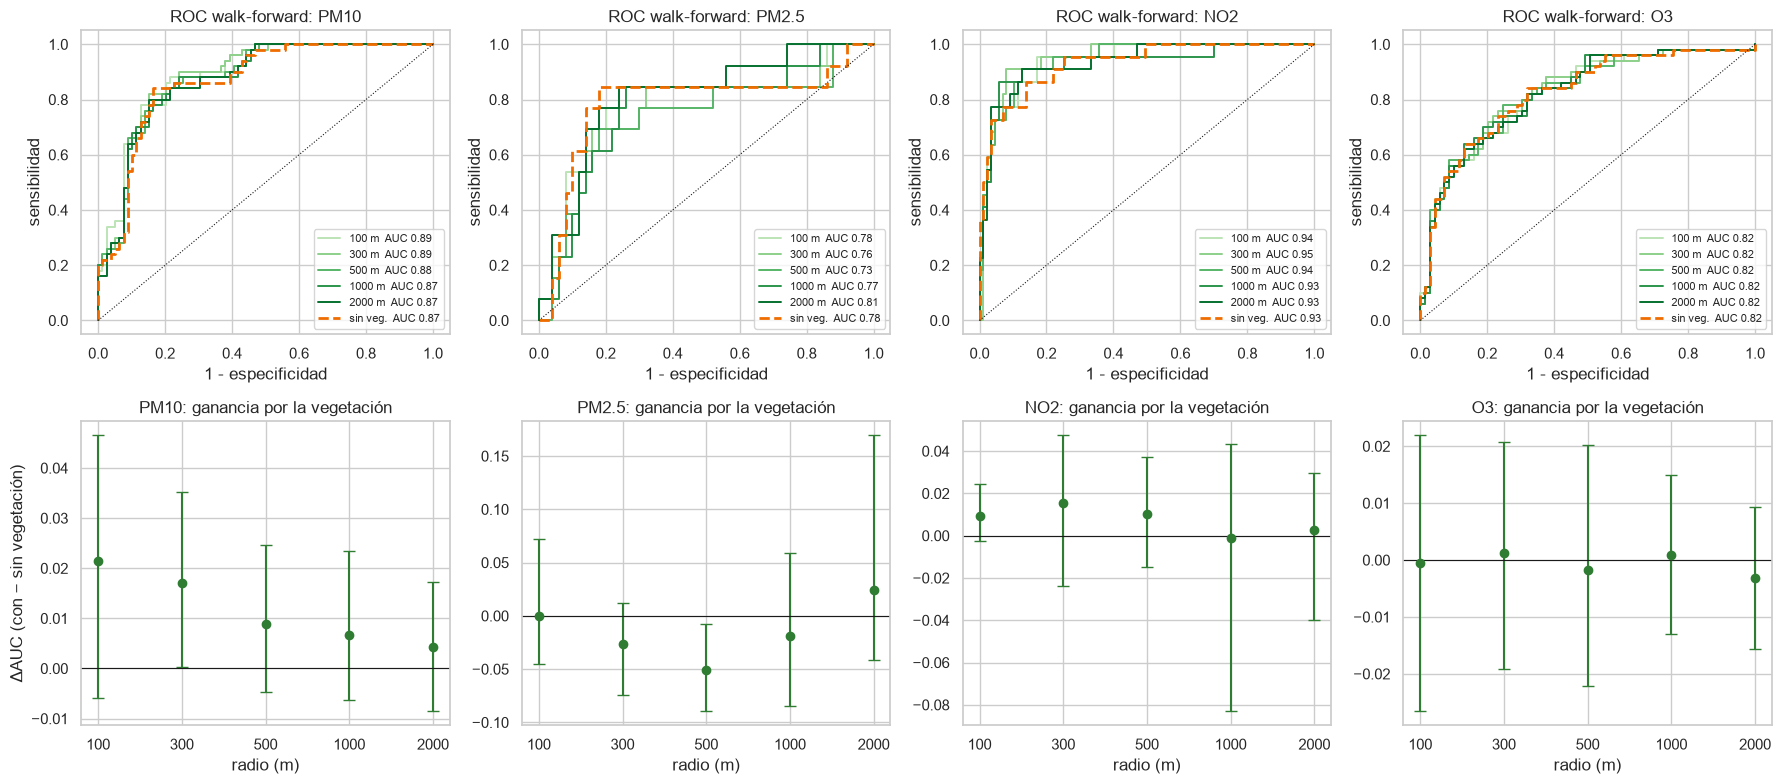

In [52]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.5 * len(CONTAMINANTES), 8))
pal = dict(zip(RADIOS, sns.color_palette("Greens", len(RADIOS) + 1)[1:]))
for j, c in enumerate(CONTAMINANTES):
    ax = axes[0, j]
    for r in RADIOS:
        t = wf_pred[(c, f"con vegetación {r} m")]; fpr, tpr, _ = roc_curve(t.y, t.proba)
        ax.plot(fpr, tpr, color=pal[r], lw=1.4, label=f"{r} m  AUC {roc_auc_score(t.y, t.proba):.2f}")
    t = wf_pred[(c, "sin vegetación")]; fpr, tpr, _ = roc_curve(t.y, t.proba)
    ax.plot(fpr, tpr, color="#EF6C00", lw=2, ls="--", label=f"sin veg.  AUC {roc_auc_score(t.y, t.proba):.2f}")
    ax.plot([0, 1], [0, 1], "k:", lw=.8); ax.set_title(f"ROC walk-forward: {c}"); ax.set_xlabel("1 - especificidad"); ax.set_ylabel("sensibilidad")
    ax.legend(loc="lower right", fontsize=8)
    ax = axes[1, j]; t = dauc.loc[c]
    ax.errorbar(range(len(t)), t["ΔAUC"], yerr=[t["ΔAUC"] - t["IC95 inf"], t["IC95 sup"] - t["ΔAUC"]], fmt="o", color="#2E7D32", capsize=4)
    ax.axhline(0, color="k", lw=.8); ax.set_xticks(range(len(t)), [str(r) for r in t.index]); ax.set_xlabel("radio (m)")
    ax.set_ylabel("ΔAUC (con − sin vegetación)" if j == 0 else ""); ax.set_title(f"{c}: ganancia por la vegetación")
plt.tight_layout(); plt.show()

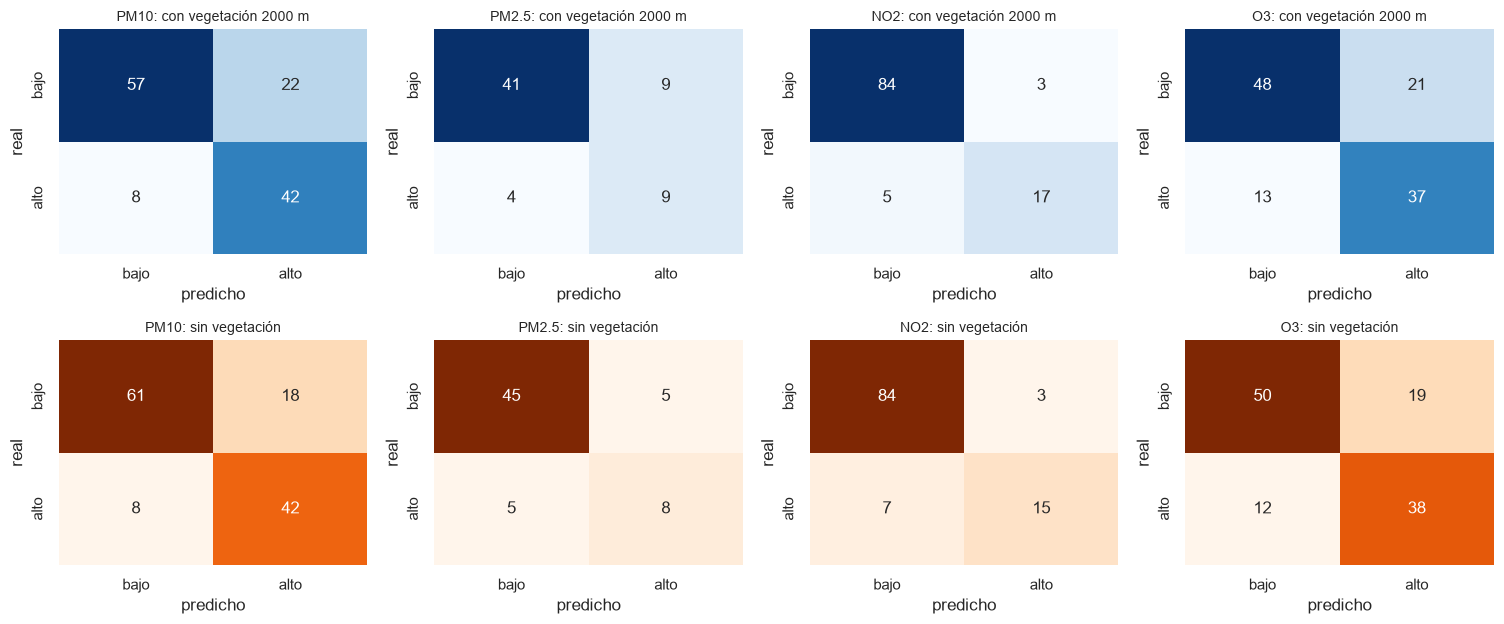

In [53]:
# Matrices de confusión walk-forward: radio principal con vegetación vs. sin vegetación
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(3.8 * len(CONTAMINANTES), 6.4))
for j, c in enumerate(CONTAMINANTES):
    for i, nombre in enumerate([f"con vegetación {RADIO} m", "sin vegetación"]):
        t = wf_pred[(c, nombre)]
        sns.heatmap(confusion_matrix(t.y, (t.proba >= .5).astype(int), labels=[0, 1]), annot=True, fmt="d", cmap="Blues" if i == 0 else "Oranges",
                    cbar=False, ax=axes[i, j], xticklabels=["bajo", "alto"], yticklabels=["bajo", "alto"])
        axes[i, j].set_title(f"{c}: {nombre}", fontsize=10); axes[i, j].set_xlabel("predicho"); axes[i, j].set_ylabel("real")
plt.tight_layout(); plt.show()

### Análisis de errores (walk-forward, modelo con vegetación del radio principal)

In [54]:
filas = []
for c in CONTAMINANTES:
    for nombre in [f"con vegetación {RADIO} m", "sin vegetación"]:
        t = wf_pred[(c, nombre)].assign(error=lambda z: ((z.proba >= .5).astype(int) != z.y).astype(int))
        filas.append(t.groupby("estacion").error.mean().rename((c, nombre)))
err = pd.DataFrame(filas).T
err.columns = pd.MultiIndex.from_tuples(err.columns)
print("Tasa de error por estación (walk-forward)")
err[("estación", f"% verde {RADIO} m")] = fijos.loc[err.index, f"verde_{RADIO}"]
display(err.sort_values(("estación", f"% verde {RADIO} m"), ascending=False))

Tasa de error por estación (walk-forward)


PM10                                PM2.5  \
         con vegetación 2000 m sin vegetación con vegetación 2000 m   
estacion                                                              
NE3                      0.091          0.091                   NaN   
SE3                      0.273          0.182                 0.714   
NO3                      0.143          0.143                   NaN   
SUR                      0.111          0.111                 0.000   
SE                       0.333          0.333                 0.000   
SE2                      0.333          0.222                 0.222   
SO2                      0.250          0.250                 0.429   
NE2                      0.250          0.250                   NaN   
NO                       0.182          0.182                   NaN   
NO2                      0.250          0.250                 0.000   
CE                       0.333          0.250                 0.333   
SO                       0.000          0.000                 0.000   
NTE2                     0.250          0.167                 0.000   

                                          NO2                 \
         sin vegetación con vegetación 2000 m sin vegetación   
estacion                                                       
NE3                 NaN                 0.000          0.000   
SE3               0.286                 0.000          0.000   
NO3                 NaN                 0.250          0.250   
SUR               0.000                 0.000          0.000   
SE                0.000                 0.000          0.000   
SE2               0.444                 0.000          0.000   
SO2               0.286                 0.000          0.000   
NE2                 NaN                 0.333          0.333   
NO                  NaN                 0.143          0.143   
NO2               0.000                 0.200          0.200   
CE                0.222                 0.083          0.083   
SO                0.000                 0.000          0.000   
NTE2              0.000                 0.167          0.333   

                            O3                      estación  
         con vegetación 2000 m sin vegetación % verde 2000 m  
estacion                                                      
NE3                      0.200          0.300         72.278  
SE3                      0.091          0.091         30.509  
NO3                      0.429          0.429         28.202  
SUR                      0.222          0.222         24.203  
SE                       0.333          0.333         21.386  
SE2                      0.143          0.000         14.006  
SO2                      0.500          0.333         12.753  
NE2                      0.100          0.100         11.377  
NO                       0.333          0.333         11.266  
NO2                      0.286          0.286         11.125  
CE                       0.500          0.417          4.946  
SO                       0.333          0.333          2.886  
NTE2                     0.200          0.200          0.560

# Variables más importantes
OR por 1 DE (IC 95 %, cluster), radio principal: modelo con vegetación (izquierda de cada par) y sin vegetación.

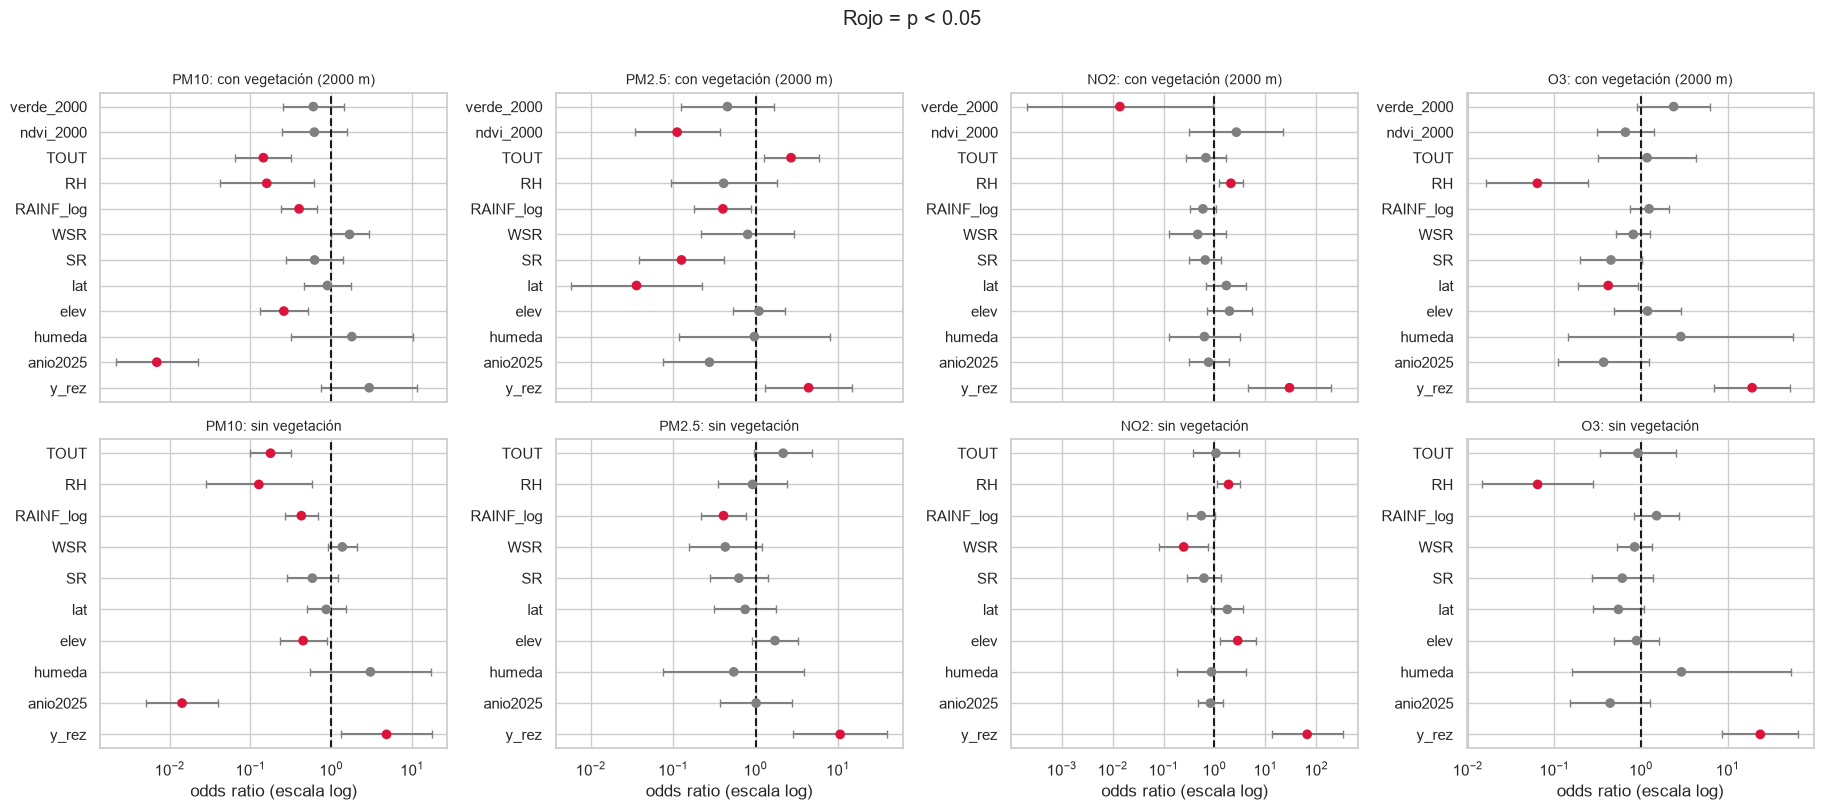

con veg.                   sin veg.                  
                         PM10 PM2.5   NO2    O3     PM10 PM2.5   NO2    O3
|coef| estandarizado                                                      
anio2025                4.971 1.287 0.266 0.994    4.251 0.015 0.185 0.820
TOUT                    1.935 0.992 0.388 0.159    1.731 0.771 0.067 0.081
RH                      1.838 0.891 0.740 2.754    2.063 0.084 0.636 2.747
elev                    1.351 0.095 0.677 0.172    0.802 0.542 1.050 0.120
y_rez                   1.080 1.481 3.389 2.949    1.574 2.363 4.189 3.167
RAINF_log               0.918 0.911 0.523 0.214    0.853 0.894 0.596 0.414
humeda                  0.586 0.033 0.456 1.055    1.116 0.609 0.134 1.073
WSR                     0.521 0.219 0.760 0.208    0.313 0.847 1.392 0.171
verde_2000              0.511 0.786 4.275 0.867      NaN   NaN   NaN   NaN
ndvi_2000               0.483 2.190 0.988 0.415      NaN   NaN   NaN   NaN
SR                      0.475 2.068 0.418 0.800    0.539 0.465 0.476 0.499
lat                     0.110 3.324 0.539 0.873    0.143 0.292 0.585 0.602

In [55]:
fig, axes = plt.subplots(2, len(CONTAMINANTES), figsize=(4.6 * len(CONTAMINANTES), 8), sharex="col")
for j, c in enumerate(CONTAMINANTES):
    for i, (nombre, tb) in enumerate([(f"con vegetación ({RADIO} m)", tablas[c]), ("sin vegetación", tablas_sv[c])]):
        ax = axes[i, j]; t = tb.drop(index="const").iloc[::-1]; sig = t.p < 0.05
        ax.errorbar(t.OR, range(len(t)), xerr=[t.OR - t.IC95_inf, t.IC95_sup - t.OR], fmt="none", ecolor="gray", capsize=3)
        ax.scatter(t.OR, range(len(t)), c=np.where(sig, "crimson", "gray"), zorder=3)
        ax.axvline(1, color="k", ls="--"); ax.set_xscale("log"); ax.set_title(f"{c}: {nombre}", fontsize=10)
        ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
        if i == 1: ax.set_xlabel("odds ratio (escala log)")
plt.suptitle("Rojo = p < 0.05", y=1.01); plt.tight_layout(); plt.show()

imp = pd.concat({"con veg.": pd.DataFrame({c: tablas[c]["coef"].abs() for c in CONTAMINANTES}),
                 "sin veg.": pd.DataFrame({c: tablas_sv[c]["coef"].abs() for c in CONTAMINANTES})}, axis=1).drop(index="const")
imp.sort_values(("con veg.", CONTAMINANTES[0]), ascending=False).rename_axis("|coef| estandarizado")

# Comparación final: modelo con vegetación vs. sin vegetación
Una fila por contaminante y radio: significancia de la vegetación (Wald conjunto con cluster), ajuste en entrenamiento (ΔAIC) y desempeño fuera de muestra (walk-forward). La última fila de cada contaminante es el modelo sin vegetación.

In [56]:
filas = []
for c in CONTAMINANTES:
    for r in RADIOS + ["sin vegetación"]:
        nombre = f"con vegetación {r} m" if r != "sin vegetación" else r
        w = res_wf.loc[(c, nombre)]; v = veg_radio.loc[(c, r)]
        fila = {"contaminante": c, "modelo": nombre, "p Wald veg.": v.get("p Wald conjunto", np.nan), "ΔAIC": v["ΔAIC vs sin veg."],
                "McFadden R2": v["McFadden R2"], "AUC wf": w["AUC"], "exactitud wf": w["exactitud"], "precisión wf": w["precisión"],
                "sensibilidad wf": w["sensibilidad"], "F1 wf": w["F1"], "Brier wf": w["Brier"]}
        if r != "sin vegetación": fila.update({"ΔAUC (IC95)": f"{dauc.loc[(c, r), 'ΔAUC']:+.3f} ({dauc.loc[(c, r), 'IC95 inf']:+.3f}, {dauc.loc[(c, r), 'IC95 sup']:+.3f})"})
        filas.append(fila)
    p = res_wf.loc[(c, "referencia: persistencia")]
    filas.append({"contaminante": c, "modelo": "referencia: persistencia", "exactitud wf": p["exactitud"], "precisión wf": p["precisión"],
                  "sensibilidad wf": p["sensibilidad"], "F1 wf": p["F1"]})
final = pd.DataFrame(filas).set_index(["contaminante", "modelo"])
final

p Wald veg.    ΔAIC  McFadden R2  \
contaminante modelo                                                       
PM10         con vegetación 100 m            0.004 -12.948        0.568   
             con vegetación 300 m            0.006  -7.473        0.545   
             con vegetación 500 m            0.020  -4.503        0.532   
             con vegetación 1000 m           0.020  -4.216        0.531   
             con vegetación 2000 m           0.005  -3.072        0.526   
             sin vegetación                    NaN   0.000        0.496   
             referencia: persistencia          NaN     NaN          NaN   
PM2.5        con vegetación 100 m            0.073  -2.274        0.350   
             con vegetación 300 m            0.133  -0.427        0.351   
             con vegetación 500 m            0.015   0.576        0.343   
             con vegetación 1000 m           0.000  -3.725        0.379   
             con vegetación 2000 m           0.001  -8.853        0.422   
             sin vegetación                    NaN   0.000        0.314   
             referencia: persistencia          NaN     NaN          NaN   
NO2          con vegetación 100 m            1.000   2.469        0.550   
             con vegetación 300 m            0.001 -16.699        0.663   
             con vegetación 500 m            0.010 -11.438        0.632   
             con vegetación 1000 m           0.012 -14.310        0.649   
             con vegetación 2000 m           0.069  -5.120        0.595   
             sin vegetación                    NaN   0.000        0.541   
             referencia: persistencia          NaN     NaN          NaN   
O3           con vegetación 100 m            0.007  -5.366        0.520   
             con vegetación 300 m            0.018  -7.092        0.527   
             con vegetación 500 m            0.020  -5.231        0.520   
             con vegetación 1000 m           0.068  -1.891        0.507   
             con vegetación 2000 m           0.200   0.229        0.498   
             sin vegetación                    NaN   0.000        0.484   
             referencia: persistencia          NaN     NaN          NaN   

                                       AUC wf  exactitud wf  precisión wf  \
contaminante modelo                                                         
PM10         con vegetación 100 m       0.890         0.752         0.625   
             con vegetación 300 m       0.885         0.806         0.692   
             con vegetación 500 m       0.877         0.798         0.688   
             con vegetación 1000 m      0.875         0.791         0.677   
             con vegetación 2000 m      0.872         0.767         0.656   
             sin vegetación             0.868         0.798         0.700   
             referencia: persistencia     NaN         0.814         0.750   
PM2.5        con vegetación 100 m       0.785         0.810         0.538   
             con vegetación 300 m       0.758         0.794         0.500   
             con vegetación 500 m       0.734         0.810         0.538   
             con vegetación 1000 m      0.766         0.794         0.500   
             con vegetación 2000 m      0.809         0.794         0.500   
             sin vegetación             0.785         0.841         0.615   
             referencia: persistencia     NaN         0.857         0.625   
NO2          con vegetación 100 m       0.941         0.908         0.833   
             con vegetación 300 m       0.948         0.899         0.762   
             con vegetación 500 m       0.943         0.908         0.800   
             con vegetación 1000 m      0.931         0.908         0.833   
             con vegetación 2000 m      0.935         0.927         0.850   
             sin vegetación             0.932         0.908         0.833   
             referencia: persistencia     NaN         0.890         0.727   
O3           con 

# Lectura de los resultados (v4)
*Cifras de la configuración por defecto: umbrales NOM de la sección 2, entrenamiento 2024-01 a 2025-06, prueba 2025-07 a 2025-12, radio principal 1000 m. Si cambias los parámetros, vuelve a leer las tablas.*

**1. Qué cambió con los umbrales normativos.** Con los límites de la NOM, los meses "altos" son 58 % en PM10 (> 50 µg/m³), 19 % en PM2.5 (> 25 µg/m³), 17 % en NO2 (> 21 ppb) y 39 % en O3 (> 30 ppb). Ya no están balanceados como con la mediana, y en PM el semestre de prueba es mucho más limpio que el entrenamiento (PM10: 70 % de meses altos en entrenamiento contra 23 % en prueba). **PM2.5 queda con solo 28 eventos en entrenamiento y 1 en el corte de prueba**, así que su corte único no se puede interpretar y sus coeficientes son frágiles (≈ 2.5 eventos por parámetro). Para O3 el umbral de 30 ppb es una decisión del equipo (la NOM no tiene un límite comparable con promedios mensuales).

**2. ¿Es significativa la vegetación?** (objetivo principal)

| | Cobertura verde (entre estaciones) | NDVI | ¿Robusto? |
|---|---|---|---|
| **NO2** | Asociación protectora en 300–2000 m (Wald cluster p ≤ 0.06; Firth LR p = 0.004–0.011 en 500–2000 m; ΔAIC −4.7 a −10.5) | No significativo | **Sí en dirección, no en magnitud** |
| **PM10** | OR 0.32–0.65 (p < 0.05 en 100, 300, 1000 y 2000 m), pero solo al controlar la ubicación y depende de NE3 | Protector a 100 y 300 m (OR 0.31 y 0.38) | **No** |
| **PM2.5** | Nada en ningún radio (p > 0.2) | Protector a 500, 1000 y 2000 m (OR 0.65, 0.40, 0.30) | Débil (pocos eventos) |
| **O3** | Solo a 100 m y con signo contrario (OR 1.71, p = 0.033), es decir, solo NE3 | No significativo | **No** |

* **NO2: la evidencia más consistente.** En el entrenamiento, **las cinco estaciones más verdes a 1000 m (≥ 10.8 % de cobertura) no tuvieron ningún mes con NO2 > 21 ppb**. Eso produce *separación*: la máxima verosimilitud manda el OR de `verde` a ≈ 0, así que **la magnitud del efecto no es interpretable** (por eso se agregó Firth, que aun así da OR de 0.001–0.04 por 1 DE en 500–2000 m). La dirección sí es estable: el efecto sigue siendo significativo en 10–13 de los 15 ajustes que quitan una estación, y a nivel estación (15 puntos, sin modelo) la correlación entre el % de meses altos y la vegetación es negativa en todos los radios (cobertura verde ρ = −0.43 a −0.49, p = 0.06–0.11; NDVI medio ρ = −0.55 a 1000 m, p = 0.035, y ρ = −0.61 a 2000 m, p = 0.017). A 100 m no se ve nada porque solo NE3 tiene cobertura verde a esa distancia. **Precaución:** el NO2 viene sobre todo del tráfico y las estaciones más verdes están en la periferia; sin una variable de tráfico o de urbanización, la vegetación puede estar midiendo "menos ciudad alrededor" y no un efecto de la vegetación como tal.
* **PM10: no es robusto.** El efecto de la cobertura verde aparece en el modelo final (con `lat` y `elev`) pero **desaparece sin la ubicación** (spec. A: OR 0.82–1.32, p ≥ 0.16 en todos los radios). Al **quitar NE3** el OR se invierte (1000 m: 0.45 → 7.4; 500 m: → 519; 300 m: → 2.9 × 10⁵), y a nivel estación no hay correlación con la cobertura verde (ρ entre −0.44 y 0.27, todos con p > 0.1). El ΔAIC grande a 100 m (−17.6) es en realidad "NE3 es diferente", porque a ese radio `verde_100` solo distingue a NE3 del resto. El NDVI a 100 y 300 m sí va en sentido protector y se mantiene con efecto fijo por estación (spec. C: OR 0.59 y 0.68), lo que apunta a algo de efecto temporal local. Pero también depende de NE3 (ρ del NDVI medio a 100 m = −0.58, p = 0.025).
* **PM2.5:** la cobertura verde no es significativa en ningún radio. El **NDVI mensual** sí (500–2000 m; Firth conjunto p = 0.03–0.07) y conserva la dirección con efecto fijo por estación (C: OR 0.60–0.70): los meses con más verdor tienden a tener menos PM2.5 alto, aun controlando lluvia y temporada. Con 28 eventos se debe tomar como pista.
* **O3:** no hay un efecto protector. Con errores agrupados ningún radio es significativo salvo 100 m (NE3), y el signo es positivo (más verde → más probabilidad de O3 alto). Eso es coherente con que en la periferia hay menos NO que consuma el ozono (titulación), y no indica que la vegetación genere ozono. La prueba de Firth da p bajos en 100–1000 m (0.003–0.017), pero ignora el agrupamiento por estación, así que es optimista.

**3. ¿Qué radio usar?** Ningún radio es el mejor para los cuatro contaminantes. Por ΔAIC, el mejor radio es 1000 m en NO2 (−10.5), 500 m en O3 (−4.1) y 2000 m en PM2.5 (−2.8). En PM10 sale 100 m, que es el artefacto de NE3; quitándolo, el mejor es 300 m. **Los radios de 500 a 2000 m dan conclusiones parecidas entre sí; 100 m no sirve para la cobertura verde** (solo NE3 tiene verde a esa distancia y en PM2.5 ni siquiera se puede estimar). Se mantiene 1000 m como radio principal y conviene reportar 500 y 2000 m como sensibilidad. A 2000 m, en PM2.5, la colinealidad sube (VIF de `verde` = 8.0).

**4. Modelo con vegetación vs. sin vegetación.**
* **Ajuste (entrenamiento):** la vegetación mejora el McFadden R² en 0.02–0.08 y el AIC en NO2 (−10.5 a 1000 m). En PM10, PM2.5 y O3 la mejora a 1000 m es mínima o nula (ΔAIC −0.5, +0.3 y −1.4).
* **Precisión fuera de muestra (walk-forward, 65–135 predicciones):** **la vegetación casi no mejora la predicción.** La diferencia de AUC va de −0.036 a +0.026. Solo en PM10 a 300 y 500 m el intervalo bootstrap excluye 0, con una ganancia de +0.02 y +0.01. En PM2.5 a 300 y 500 m la vegetación empeora ligeramente la predicción (−0.03 y −0.04, con intervalos que apenas tocan 0): es sobreajuste con pocos eventos. La exactitud cambia como máximo ±0.04 (entre 1 y 6 predicciones) y el Brier es prácticamente igual. A 1000 m, la exactitud con vs. sin vegetación es: PM10 0.793 vs. 0.807, PM2.5 0.815 vs. 0.831, NO2 0.912 vs. 0.903, O3 0.715 vs. 0.724.
* **Contra la persistencia** ("este mes será igual que el anterior"): en exactitud, ambos modelos quedan por debajo o empatados en PM10 (0.82), PM2.5 (0.86) y O3 (0.79). En NO2 quedan ligeramente arriba (0.90–0.92 vs. 0.89). Lo que el modelo sí aporta sobre la persistencia es una probabilidad bien ordenada (AUC 0.76–0.95). La capacidad predictiva viene de `y_rez`, la meteorología (temperatura y lluvia en PM, humedad en O3 y NO2) y `anio2025`, no de la vegetación.
* **Lectura conjunta:** que la vegetación sea significativa en NO2 pero no mejore la predicción no es contradictorio. La cobertura verde es una característica fija de cada estación: explica *qué estaciones* tienden a tener meses altos, algo que `y_rez` (el mes anterior de la misma estación) ya captura casi por completo al predecir un mes adelante.

**5. Supuestos.** Con `y_rez`, la autocorrelación residual queda sin evidencia de dependencia (|ρ| ≤ 0.12, p ≥ 0.12). Hosmer-Lemeshow no rechaza el ajuste en ningún modelo (p ≥ 0.23). En la I de Moran, solo el residuo de NO2 con vegetación muestra autocorrelación espacial *negativa* (I = −0.18, p = 0.027): estaciones vecinas con residuos opuestos, posiblemente por la separación. El resto da p > 0.08. VIF ≤ 5.4, salvo PM2.5 a 2000 m.

**6. Ajuste metodológico en el walk-forward.** En v3, en los primeros pasos del walk-forward `anio2025` se estimaba con 1 o 2 meses de 2025 y capturaba la estacionalidad de enero y febrero. Ahora solo entra con al menos 6 meses de 2025 (`MIN_MESES_2025`). Esto subió el AUC walk-forward de O3 de ≈ 0.70 a 0.84 y no cambia el corte único, que tiene 6 meses de 2025.

**7. Recomendaciones.**
* Para el reporte: *"la vegetación se asocia de forma consistente solo con el NO2: las estaciones más verdes casi no registran meses por encima del límite anual de la NOM. La magnitud no es estimable (separación) y puede reflejar menor urbanización. En PM10 la asociación depende de una sola estación (NE3), en PM2.5 hay una señal temporal del NDVI y en O3 no hay efecto protector. Incluir la vegetación no mejora la predicción fuera de muestra."*
* Para separar vegetación de urbanización hace falta una covariable de **tráfico o densidad vial** (aforos, longitud de vialidades o % construido no vegetal en el radio) y, de ser posible, más estaciones con contraste de vegetación.
* Para O3 conviene probar la **radiación solar (SR)**, que está en la base y es el motor de la formación de ozono pero no está en el modelo.
* Para alinear mejor con la NOM, lo ideal sería contar **días por mes que exceden el límite de 24 h** (PM) o el de 8 h (O3), en lugar de comparar promedios mensuales. Eso requiere los datos diarios u horarios.